# Myopia Prediction - Machine Learning Project (revised version)

**Objective:** Build machine learning classification models to predict four myopia-related targets from clinical, lifestyle, and ophthalmological data collected from medical students at the University of Navarra.

**Targets:**

| Target | Type | Classes | Description |
|--------|------|---------|-------------|
| **M** | Binary | SI / NO | Has myopia? |
| **MM** | Binary | SI / NO | Has myopia magna (>6 diopters)? |
| **Combo** | Multi-class | M / MM / C | Combined myopia classification |
| **DCombo** | Multi-class | C / M1 / M2 / MM | Detailed myopia sub-classification |

> **Logical constraints between targets** (checked against the training labels in Phase 1):
> - **MM=SI ⇒ DCombo=MM** (the reverse is *not* true: 8 training students have DCombo=MM but MM=NO)
> - **M=NO ⇔ DCombo=C**
> - **Combo = merge(DCombo)**: C → C, M1/M2 → M, MM → MM

### What changed with respect to `main.ipynb`

| # | Change | Why |
|---|--------|-----|
| 1 | New post-processing rules (the three constraints above) | The old rule "M=SI and MM=NO ⇒ Combo=M" contradicted 8 training students and erased correct MM predictions |
| 2 | Final **Combo is derived from DCombo** instead of being predicted by its own model | Guarantees Combo and DCombo are always consistent |
| 3 | When a rule forces DCombo away from C, we pick the most probable myopic class (`predict_proba`) instead of always M1 | Uses the model's own information instead of an arbitrary default |
| 4 | The post-processing is **validated on out-of-fold predictions** | We measure whether the rules help instead of assuming it |
| 5 | Cross-validation uses **`RepeatedStratifiedKFold`** (5 folds x 10 repeats) | With 132 samples (only 10 MM=SI) a single 5-fold split gives very noisy scores |
| 6 | Imputation moved **inside each model's `Pipeline`** (`SimpleImputer`) | Before, medians were computed on the full training set before CV (data leakage) and the test set was partly imputed with its own medians |
| 7 | Removed 5 columns that are exact copies of others (e.g. `OD-Total = 2 x OD-Media`) and the near-constant `Grupo fot` | Duplicates give double weight to some measurements in the SVM distance and split tree importances |
| 8 | Fixed a data-entry error in `CUVAF-Media` (test row 0) | Detected by checking the arithmetic relations between columns |
| 9 | Fixed `has_family_mm_relative` for the answer "No lo se, No" (was encoded as 1) and removed silent `fillna(0)` in the encoding | Unknown answers now become NaN and are imputed, instead of silently becoming 0 / 1 |
| 10 | Text corrections (feature counts, SVM `gamma`, conclusions) | Report must match the code and outputs |

Hyperparameters are kept **exactly as in `main.ipynb`** (no tuning in this version).

In [1]:
# === Library Imports ===
try:
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns
    import warnings
    from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold,
                                         cross_validate, cross_val_predict)
    from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
    from sklearn.svm import SVC
    from sklearn.preprocessing import StandardScaler
    from sklearn.impute import SimpleImputer
    from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                                 ConfusionMatrixDisplay, classification_report)
    from sklearn.pipeline import Pipeline
except ImportError as e:
    print(f"Error importing libraries: {e}. \nYOU CAN INSTALL ALL THE LIBRARIES WITH 'pip install -r requirements.txt'.")
    raise e
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
sns.set_palette('husl')

print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## Phase 1: Data Exploring

We start by loading the data, examining its shape, data types, and missing values. Then we visualize the distributions of targets and features to identify patterns, outliers, and relationships.

In [2]:
# Load training data (features + labels) and test data (features only, no labels)
X_train_raw = pd.read_csv('X_train.csv')
Y_train = pd.read_csv('Y_train.csv')
X_test_raw = pd.read_csv('X_test.csv')

print(f"Training features: {X_train_raw.shape[0]} samples x {X_train_raw.shape[1]} features")
print(f"Training labels:   {Y_train.shape[0]} samples x {Y_train.shape[1]} targets")
print(f"Test features:     {X_test_raw.shape[0]} samples x {X_test_raw.shape[1]} features")
print(f"\nTarget columns: {Y_train.columns.tolist()}")

Training features: 132 samples x 49 features
Training labels:   132 samples x 4 targets
Test features:     24 samples x 49 features

Target columns: ['M', 'MM', 'Combo', 'DCombo']


In [3]:
# First 5 rows of the training features
X_train_raw.head()

,fecha,edad,sexo,origen antepasados (españa),origen antepasados (extranjeros),hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,...,OS-DS,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal
0,2/11/20,22,Mujer,Asturias,NaN,0.0,0.0,4.0,4.0,40,...,0.238059,2.256667,0.564167,0.842300,0.905000,1.279863,1.810000,0.223333,0.160278,0.446667
1,2/17/20,23,Mujer,Navarra,NaN,5.0,2.0,2.0,9.0,20,...,2.585654,8.026667,2.006667,1.887316,3.620833,0.503224,7.241667,0.392500,0.102530,0.785000
2,3/10/20,22,Mujer,Bizkaia,NaN,2.0,3.0,8.0,13.0,30,...,0.431335,12.710000,3.177500,0.743668,3.152500,1.248043,6.305000,3.202500,0.314663,6.405000
3,2/26/20,22,Mujer,"Navarra, Extremadura, Cataluña, Aragón",España,0.0,2.0,13.0,15.0,54,...,0.626968,3.551667,0.887917,0.877145,1.003333,1.418928,2.006667,0.772500,0.491439,1.545000
4,2/19/20,23,Mujer,Toledo,NaN,3.0,0.0,0.0,3.0,56,...,1.269257,1.795000,0.448750,0.897500,0.897500,1.269257,1.795000,0.000000,0.000000,0.000000


In [4]:
# Data types overview
print("=== Data Types ===\n")
for i, (col, dtype) in enumerate(X_train_raw.dtypes.items()):
    print(f"  {i:2d}. {col:45s} -> {dtype}")

n_num = len(X_train_raw.select_dtypes(include=[np.number]).columns)
n_cat = X_train_raw.shape[1] - n_num
print(f"\nNumerical: {n_num} | Categorical/String: {n_cat}")

=== Data Types ===

   0. fecha                                         -> str
   1. edad                                          -> int64
   2. sexo                                          -> str
   3. origen antepasados (españa)                   -> str
   4. origen antepasados (extranjeros)              -> str
   5. hº deporte sem                                -> float64
   6. hº naturaleza sem                             -> float64
   7. hº ocio exteriores sem                        -> float64
   8. horas exterior sem                            -> float64
   9. hº estudiar sem                               -> int64
  10. hº ocio inter sem                             -> int64
  11. hº act.cerca sem                              -> float64
  12. horas interior sem                            -> float64
  13. Ratio Cerca/Lejos                             -> float64
  14. Exterior Mucho                                -> str
  15. Interior Mcho                                 -> str
  

=== Columns with Missing Values ===

                                  Count  Percent (%)  Test count
hº act.cerca sem                    132        100.0          24
origen antepasados (extranjeros)     98         74.2          18
Grupo fot                            24         18.2           4
fototipo                             21         15.9           4
Familiar miope num.                   4          3.0           0
pat. Ret. Miop magna                  2          1.5           1
origen antepasados (españa)           2          1.5           1
hº ocio exteriores sem                2          1.5           0
horas interior sem                    1          0.8           0
familiar miope                        1          0.8           0
hº naturaleza sem                     0          0.0           2


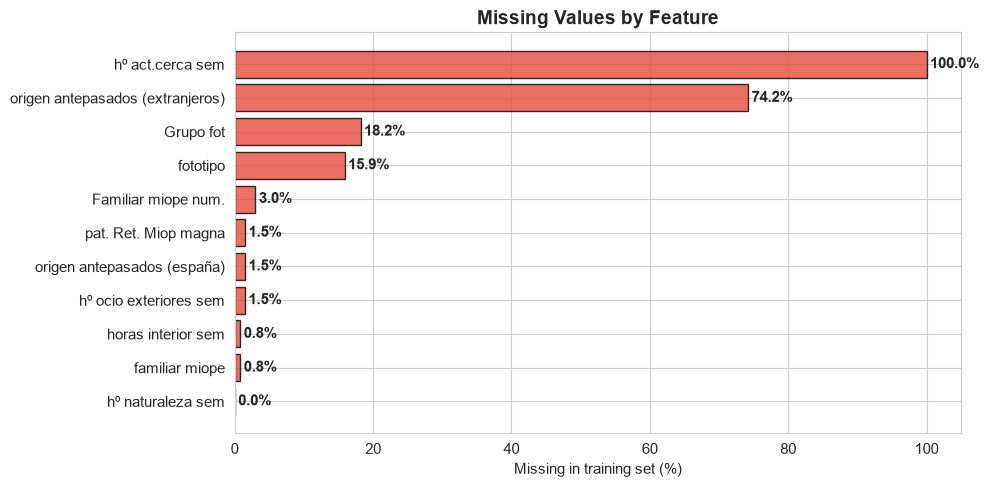

In [5]:
# Missing values analysis (training and test)
missing = X_train_raw.isnull().sum()
missing_pct = (missing / len(X_train_raw) * 100).round(1)
missing_df = pd.DataFrame({'Count': missing, 'Percent (%)': missing_pct,
                           'Test count': X_test_raw.isnull().sum()})
missing_df = missing_df[(missing_df['Count'] > 0) | (missing_df['Test count'] > 0)]
missing_df = missing_df.sort_values('Percent (%)', ascending=False)

print("=== Columns with Missing Values ===\n")
print(missing_df.to_string())

# Visualize (training set)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(missing_df.index, missing_df['Percent (%)'], color='#e74c3c', edgecolor='black', alpha=0.8)
ax.set_xlabel('Missing in training set (%)')
ax.set_title('Missing Values by Feature', fontsize=14, fontweight='bold')
ax.invert_yaxis()
for bar, pct in zip(bars, missing_df['Percent (%)']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{pct}%', va='center', fontweight='bold')
plt.tight_layout()
plt.show()

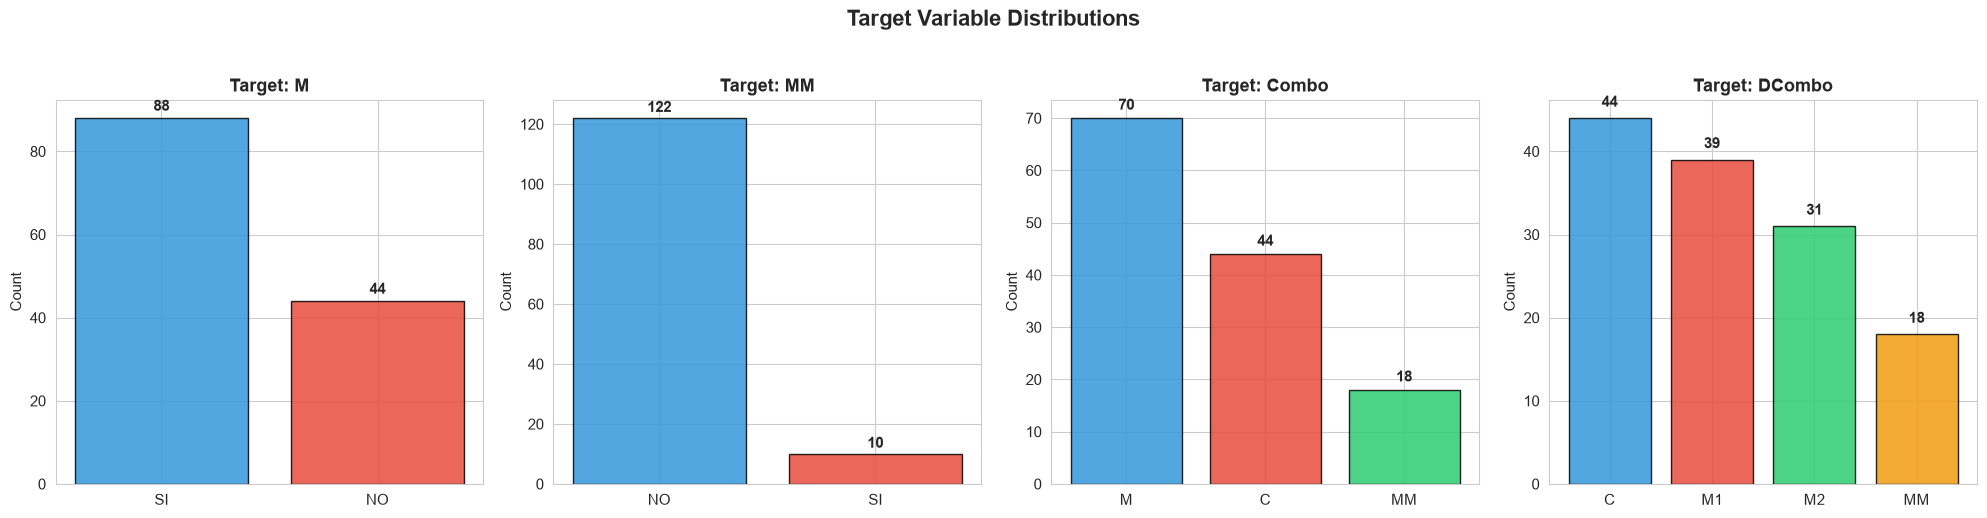


=== Class Distribution Summary ===

  M       : {'SI': 88, 'NO': 44}  (total=132)
  MM      : {'NO': 122, 'SI': 10}  (total=132)
  Combo   : {'M': 70, 'C': 44, 'MM': 18}  (total=132)
  DCombo  : {'C': 44, 'M1': 39, 'M2': 31, 'MM': 18}  (total=132)


In [6]:
# Target distribution analysis
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
palette = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6']

for i, col in enumerate(Y_train.columns):
    vc = Y_train[col].value_counts()
    bars = axes[i].bar(vc.index, vc.values, color=palette[:len(vc)], edgecolor='black', alpha=0.85)
    axes[i].set_title(f'Target: {col}', fontsize=13, fontweight='bold')
    axes[i].set_ylabel('Count')
    for bar in bars:
        axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
                     f'{int(bar.get_height())}', ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.suptitle('Target Variable Distributions', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Print summary
print("\n=== Class Distribution Summary ===\n")
for col in Y_train.columns:
    counts = {k: int(v) for k, v in Y_train[col].value_counts().items()}
    print(f"  {col:8s}: {counts}  (total={sum(counts.values())})")

### Relationship between the 4 targets

Before deciding any post-processing rule, we look at **which label combinations actually occur** in the training data. A rule is only valid if no training student breaks it.

In [7]:
# All label combinations that appear in the training set
print("=== Label combinations in the training set ===\n")
print(pd.crosstab([Y_train['M'], Y_train['MM']], [Y_train['Combo'], Y_train['DCombo']]))

# Check each constraint on the training labels
merge_map = {'C': 'C', 'M1': 'M', 'M2': 'M', 'MM': 'MM'}
mm_yes = Y_train['MM'] == 'SI'
print("\n=== Constraint check on training labels ===\n")
print(f"  MM=SI => DCombo=MM          : {(Y_train.loc[mm_yes, 'DCombo'] == 'MM').sum()} / {mm_yes.sum()} students")
print(f"  M=NO  <=> DCombo=C          : {((Y_train['M'] == 'NO') == (Y_train['DCombo'] == 'C')).sum()} / {len(Y_train)} students")
print(f"  Combo = merge(DCombo)       : {(Y_train['Combo'] == Y_train['DCombo'].map(merge_map)).sum()} / {len(Y_train)} students")

# The reverse of the first rule is NOT true
dcombo_mm_but_not_mm = ((Y_train['DCombo'] == 'MM') & (Y_train['MM'] == 'NO')).sum()
print(f"\n  DCombo=MM but MM=NO         : {dcombo_mm_but_not_mm} students  -> DCombo=MM does NOT imply MM=SI")

=== Label combinations in the training set ===

Combo    C   M      MM
DCombo   C  M1  M2  MM
M  MM                 
NO NO   44   0   0   0
SI NO    0  39  31   8
   SI    0   0   0  10

=== Constraint check on training labels ===

  MM=SI => DCombo=MM          : 10 / 10 students
  M=NO  <=> DCombo=C          : 132 / 132 students
  Combo = merge(DCombo)       : 132 / 132 students

  DCombo=MM but MM=NO         : 8 students  -> DCombo=MM does NOT imply MM=SI


The three constraints hold for **every** training student, so we can safely enforce them on the test predictions.

Note that **DCombo=MM does not imply MM=SI**: 8 students are labelled MM in DCombo/Combo but NO in the binary MM column (probably a different diopter threshold was used for each column). The original notebook assumed the opposite and, in Phase 4, overwrote every Combo/DCombo=MM prediction whenever the MM model said NO. We no longer do that.

Also, **Combo is a deterministic function of DCombo** (M1 and M2 are merged into M). Therefore, in Phase 4 we will derive Combo from the DCombo prediction, so both columns are always consistent.

### Data quality check: derived columns

Several columns are computed from others (totals, means, sums). We verify that these arithmetic relations hold, which helps to (a) find typing errors and (b) find columns that carry no extra information.

In [8]:
def check_derived_columns(df, name):
    # Each rule is 'difference that should be 0'
    rules = {
        'OD-Total = 2 x OD-Media':           df['OD-Total'] - 2 * df['OD-Media'],
        'OS-Total = 2 x OS-Media':           df['OS-Total'] - 2 * df['OS-Media'],
        'CUVAF-Total = OD-Total + OS-Total': df['CUVAF-Total'] - (df['OD-Total'] + df['OS-Total']),
        'CUVAF-Total = 4 x CUVAF-Media':     df['CUVAF-Total'] - 4 * df['CUVAF-Media'],
        'Suma Nasal = 2 x Promedio Nasal':   df['Suma Nasal'] - 2 * df['Promedio Nasal'],
        'Suma Temporal = 2 x Promedio Temporal': df['Suma Temporal'] - 2 * df['Promedio Temporal'],
        'LA Media = (LA OD + LA OS) / 2':    df['LA Media'] - (df['LA OD'] + df['LA OS']) / 2,
        'Ratio = interior / exterior hours': df['Ratio Cerca/Lejos'] - df['horas interior sem'] / df['horas exterior sem'],
    }
    print(f"=== {name} ===")
    for rule, diff in rules.items():
        bad_rows = df.index[diff.abs() > 0.01].tolist()
        status = 'OK' if not bad_rows else f'FAILS in rows {bad_rows}'
        print(f"  {rule:40s} {status}")
    print()

check_derived_columns(X_train_raw, 'Training set')
check_derived_columns(X_test_raw, 'Test set')

print("Test row 0 (CUVAF):")
print(X_test_raw.loc[[0], ['OD-Media', 'OS-Media', 'CUVAF-Total', 'CUVAF-Media']].to_string())
print("\nTraining rows where the ratio check fails:")
print(X_train_raw.loc[X_train_raw['horas exterior sem'] == 0,
                      ['horas exterior sem', 'horas interior sem', 'Ratio Cerca/Lejos']].to_string())

=== Training set ===
  OD-Total = 2 x OD-Media                  OK
  OS-Total = 2 x OS-Media                  OK
  CUVAF-Total = OD-Total + OS-Total        OK
  CUVAF-Total = 4 x CUVAF-Media            OK
  Suma Nasal = 2 x Promedio Nasal          OK
  Suma Temporal = 2 x Promedio Temporal    OK
  LA Media = (LA OD + LA OS) / 2           OK
  Ratio = interior / exterior hours        FAILS in rows [8, 15, 44, 106, 111]

=== Test set ===
  OD-Total = 2 x OD-Media                  OK
  OS-Total = 2 x OS-Media                  OK
  CUVAF-Total = OD-Total + OS-Total        OK
  CUVAF-Total = 4 x CUVAF-Media            FAILS in rows [0]
  Suma Nasal = 2 x Promedio Nasal          OK
  Suma Temporal = 2 x Promedio Temporal    OK
  LA Media = (LA OD + LA OS) / 2           OK
  Ratio = interior / exterior hours        OK

Test row 0 (CUVAF):
   OD-Media  OS-Media  CUVAF-Total  CUVAF-Media
0     4.265    9.7725       28.075      0.01875

Training rows where the ratio check fails:
     horas exter

**Findings:**
- `OD-Total`, `OS-Total`, `CUVAF-Total`, `Suma Nasal` and `Suma Temporal` are **exact multiples or sums of other columns**, so they add no information. We drop them in Phase 2 and keep the "Media"/"Promedio" versions.
- **Test row 0 has a typing error**: `CUVAF-Media = 0.01875`, while its own `CUVAF-Total` (28.075) and the mean of `OD-Media` and `OS-Media` both give **7.01875** (a missing "7"). Since CUVAF-Media is by definition the mean of OD-Media and OS-Media, we recompute it from them.
- `Ratio Cerca/Lejos` only "fails" for the 5 students with **0 outdoor hours**, where the ratio is a division by zero. The dataset authors filled in a large value for them, which keeps the meaning (a lot of near work compared with outdoor time), so we keep those values.
- `LA Media` is the mean of `LA OD` and `LA OS`. It is not an exact copy of either one, so we keep all three.

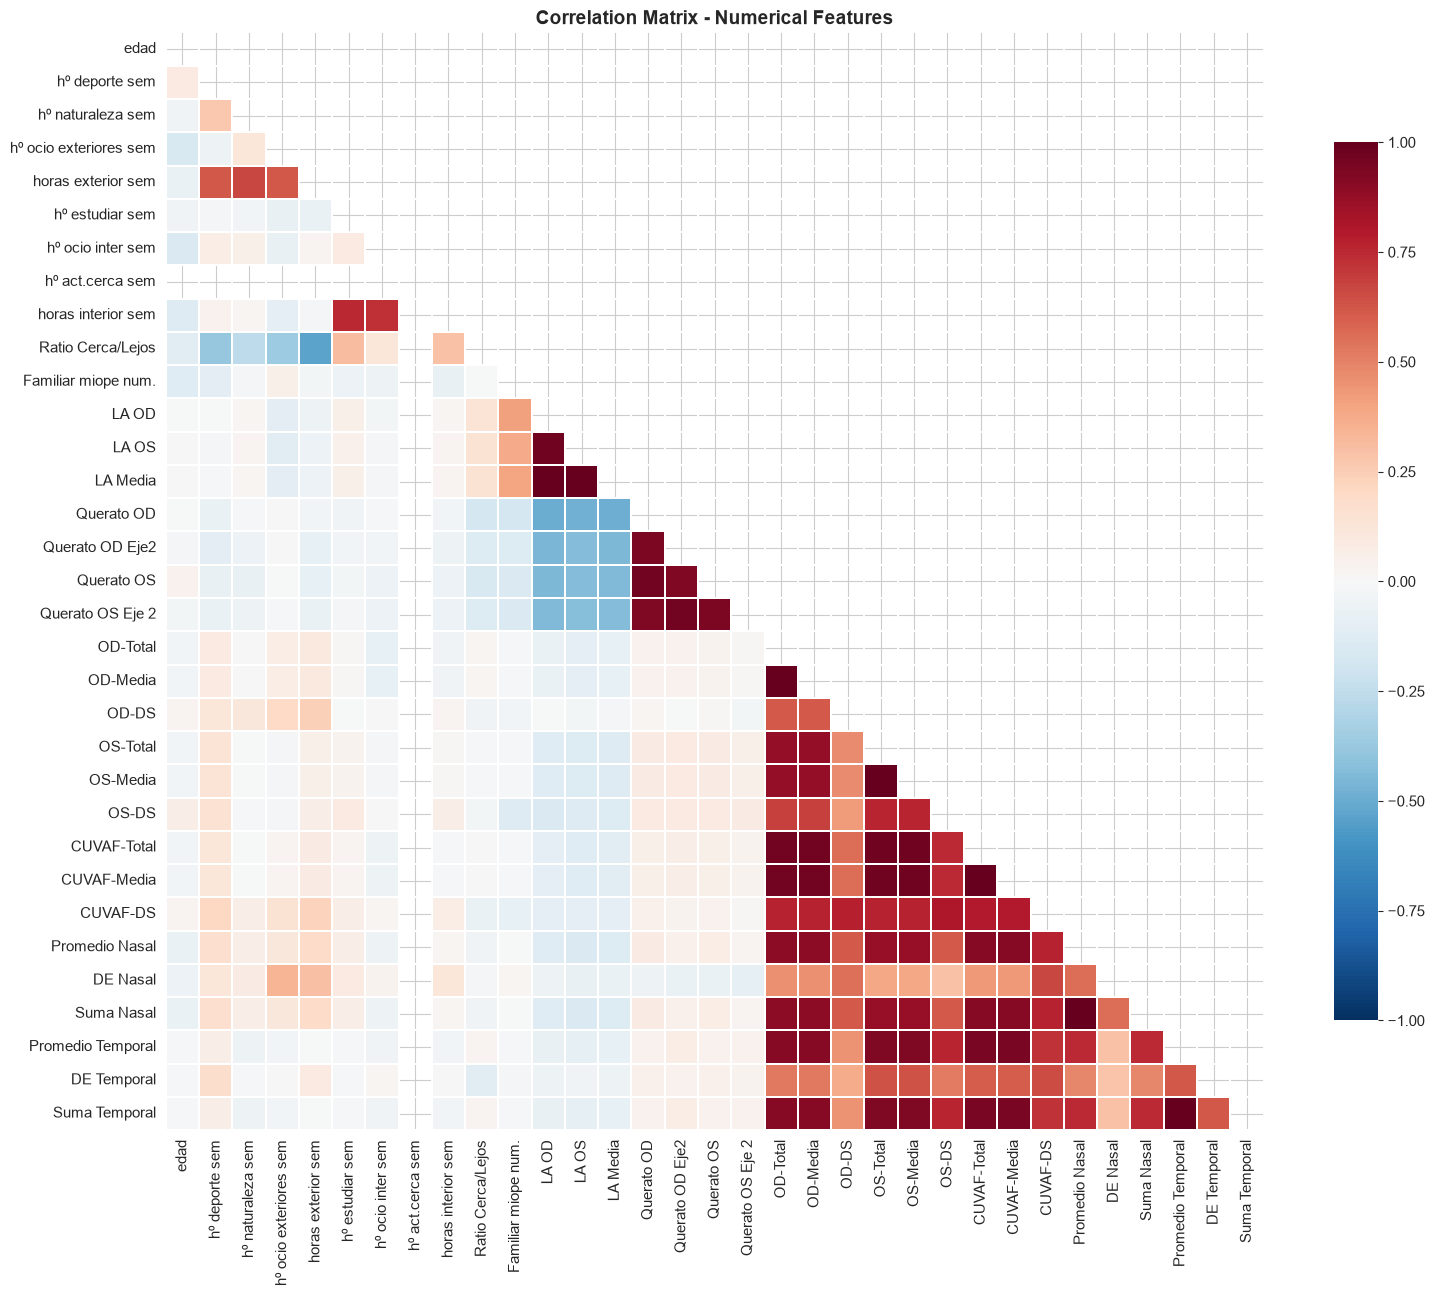


=== Highly Correlated Feature Pairs (|r| > 0.8) ===

  OD-Total                  <-> OD-Media                   r=1.000
  CUVAF-Total               <-> CUVAF-Media                r=1.000
  Promedio Nasal            <-> Suma Nasal                 r=1.000
  Promedio Temporal         <-> Suma Temporal              r=1.000
  OS-Total                  <-> OS-Media                   r=1.000
  LA OS                     <-> LA Media                   r=0.993
  LA OD                     <-> LA Media                   r=0.993
  LA OD                     <-> LA OS                      r=0.973
  OS-Media                  <-> CUVAF-Media                r=0.971
  OS-Media                  <-> CUVAF-Total                r=0.971
  OS-Total                  <-> CUVAF-Media                r=0.971
  OS-Total                  <-> CUVAF-Total                r=0.971
  Querato OD Eje2           <-> Querato OS Eje 2           r=0.968
  OD-Media                  <-> CUVAF-Total                r=0.966
  OD-Med

In [9]:
# Correlation heatmap for numerical features
num_cols = X_train_raw.select_dtypes(include=[np.number]).columns
corr = X_train_raw[num_cols].corr()

plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, annot=False,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.8},
            vmin=-1, vmax=1)
plt.title('Correlation Matrix - Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Highly correlated pairs (|r| > 0.8)
print("\n=== Highly Correlated Feature Pairs (|r| > 0.8) ===\n")
high_corr = []
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.8:
            high_corr.append((corr.columns[i], corr.columns[j], corr.iloc[i, j]))
high_corr.sort(key=lambda x: abs(x[2]), reverse=True)
for c1, c2, r in high_corr:
    print(f"  {c1:25s} <-> {c2:25s}  r={r:.3f}")

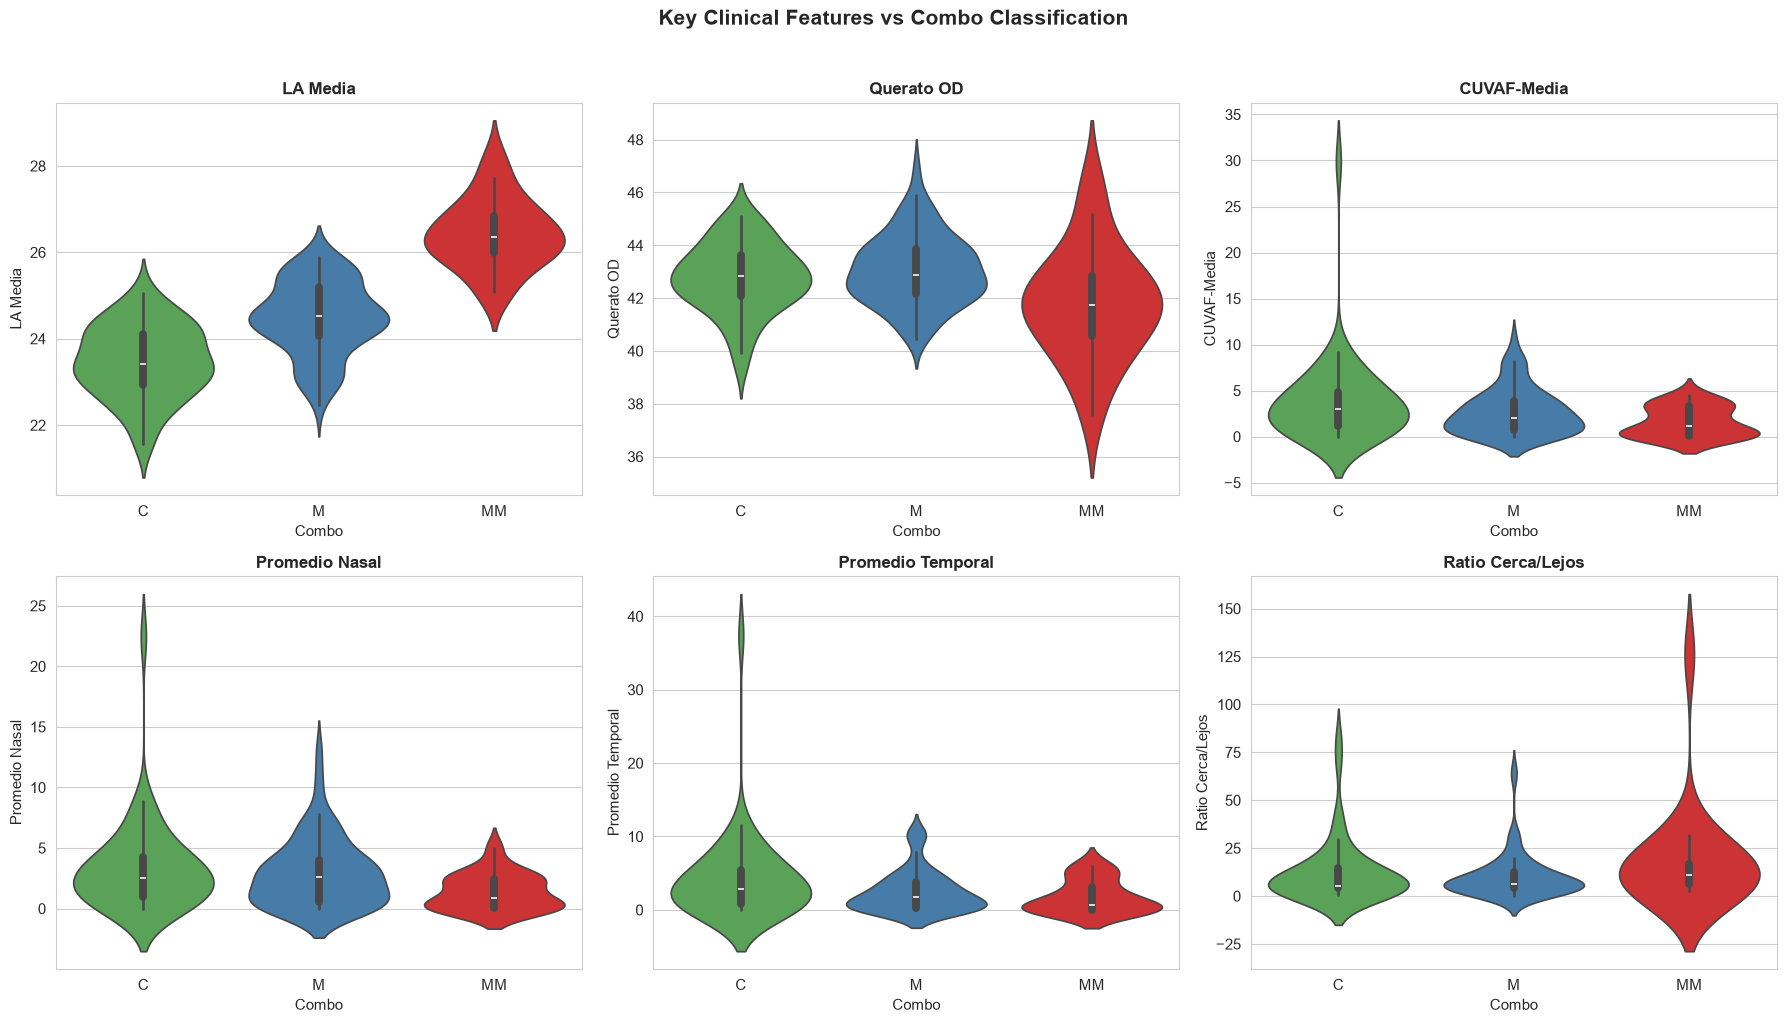

In [10]:
# Key features vs Combo (3-class: C, M, MM)

data_viz = X_train_raw.copy()
data_viz['M'] = Y_train['M'].values
data_viz['MM'] = Y_train['MM'].values
data_viz['Combo'] = Y_train['Combo'].values

# Key clinical features
key_features = ['LA Media', 'Querato OD', 'CUVAF-Media',
                'Promedio Nasal', 'Promedio Temporal', 'Ratio Cerca/Lejos']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for idx, feat in enumerate(key_features):
    ax = axes[idx // 3][idx % 3]
    sns.violinplot(data=data_viz, x='Combo', y=feat, ax=ax, palette='Set1',
                   hue='Combo', legend=False, inner='box', order=['C', 'M', 'MM'])
    ax.set_title(f'{feat}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Combo')
plt.suptitle('Key Clinical Features vs Combo Classification', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

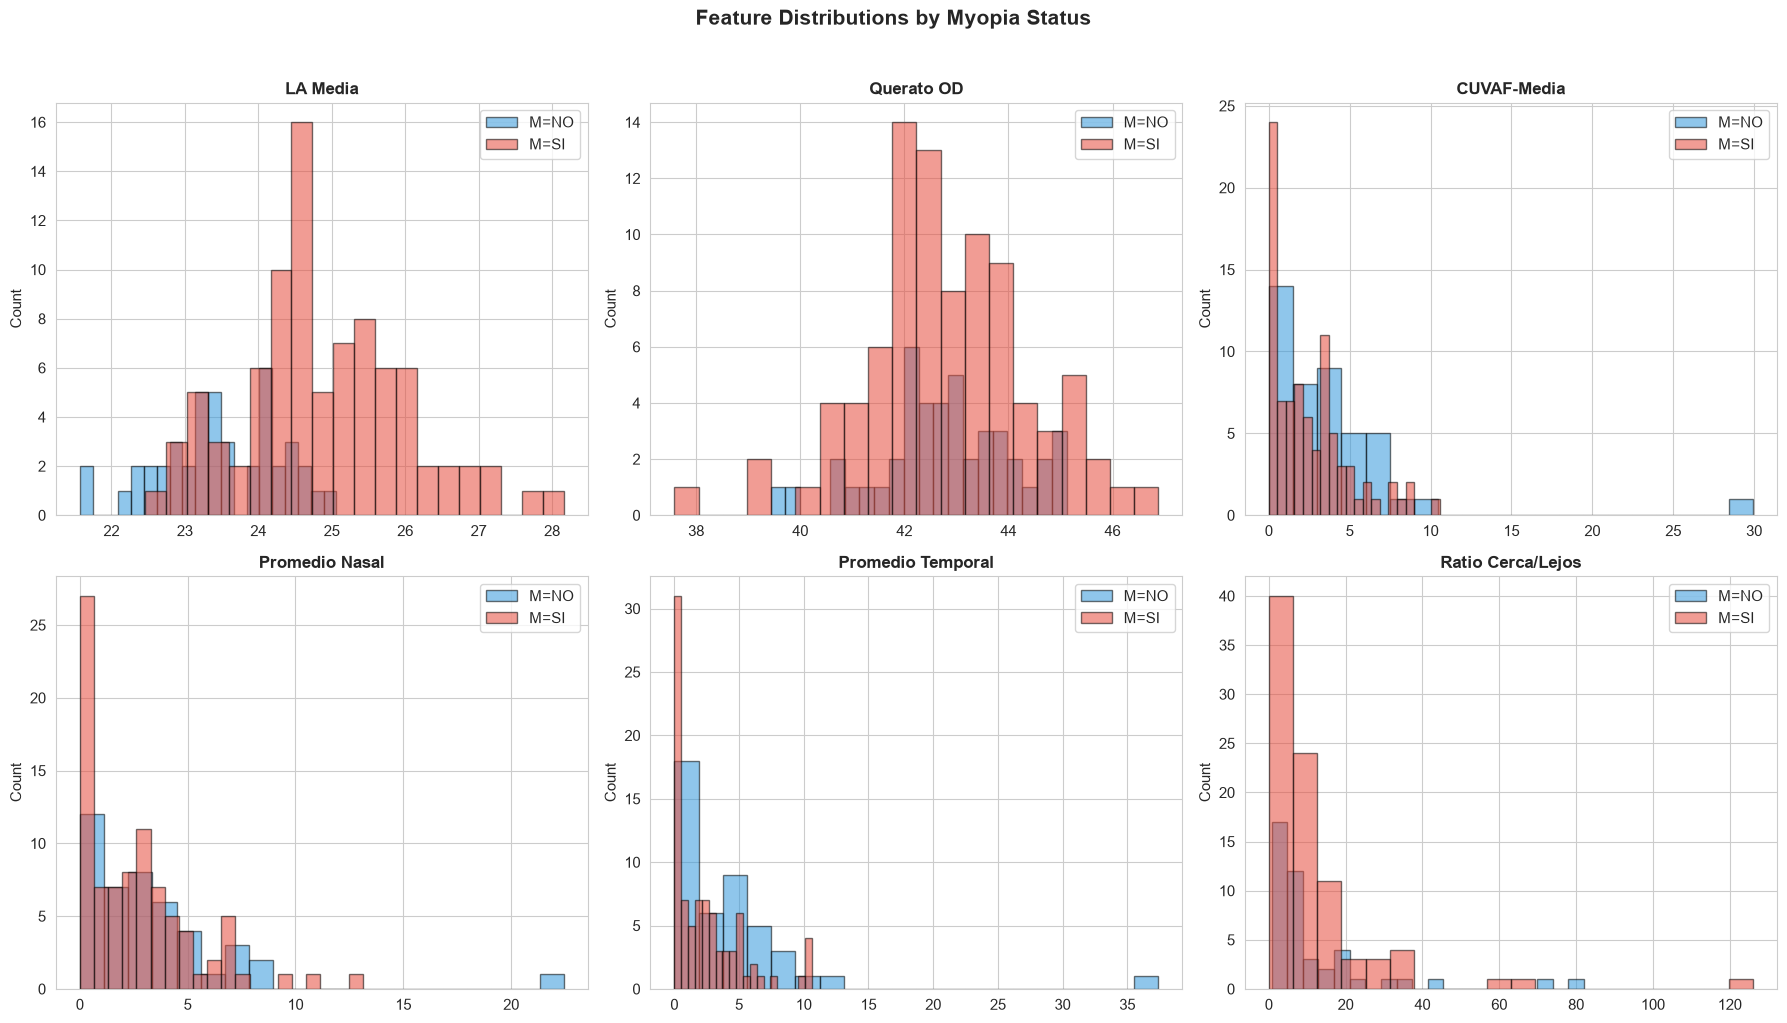

In [11]:
# Feature distributions overlaid by myopia status
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for idx, feat in enumerate(key_features):
    ax = axes[idx // 3][idx % 3]
    for label, color in zip(['NO', 'SI'], ['#3498db', '#e74c3c']):
        subset = data_viz[data_viz['M'] == label][feat].dropna()
        ax.hist(subset, bins=20, alpha=0.55, label=f'M={label}', color=color, edgecolor='black')
    ax.set_title(feat, fontsize=12, fontweight='bold')
    ax.legend()
    ax.set_ylabel('Count')
plt.suptitle('Feature Distributions by Myopia Status', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Phase 1 - Key Findings

1. **Class imbalance**: MM has only 10 positive samples (7.6%). We use `class_weight='balanced'` in all models.
2. **Missing values**: One column (hours of near activity) is 100% missing and the foreign-ancestry column is 74% missing. The test set also has 2 missing values in `hº naturaleza sem`, a column that has no missing values in training.
3. **Axial Length (LA Media)** is clearly higher in myopic patients, so it should be a strong predictor.
4. **Redundant columns**: 5 columns are exact copies (multiples or sums) of others and will be removed. Other high correlations (OD vs OS eye, LA OD vs LA OS) are real, related measurements and are kept.
5. **Data error**: test row 0 has a typo in `CUVAF-Media` that we correct.
6. **Target structure**: MM=SI ⇒ DCombo=MM, M=NO ⇔ DCombo=C and Combo = merge(DCombo) hold for all training students. **DCombo=MM does not imply MM=SI.**

---
## Phase 2: Data Cleaning

### Columns Dropped:
| Column | Reason |
|--------|--------|
| `fecha` | Measurement date - not a clinical predictor |
| `origen antepasados (españa)` | Too many unique regions, minimal predictive value |
| `origen antepasados (extranjeros)` | 74% missing, too sparse |
| `hº act.cerca sem` | 100% missing - completely unusable |
| `familiar miope` (text) | Free-text column; we keep the numeric count `Familiar miope num.` instead |
| `OD-Total`, `OS-Total`, `CUVAF-Total`, `Suma Nasal`, `Suma Temporal` | Exact copies of the Media/Promedio columns (see Phase 1) |
| `Grupo fot` | Almost constant: 106 'E', only 2 'L' and 24 missing in training; all test values are 'E' |

### Encoding Strategy:
- **Binary SI/NO columns** -> 0/1 mapping
- **`sexo`** -> Mujer=0, Hombre=1
- **`fototipo`** -> Extract the numeric value (1-5). Entries 'E'/'L' are values of `Grupo fot` typed in the wrong column, so they become NaN and are imputed
- **`Familiar MM SI/NO`** -> No=0, No lo se=1, Si=2 (ordinal)
- **`disp.elec.antes dormir`** -> Nunca=0, A veces=1, Siempre=2 (ordinal)
- **`pat. Ret. Miop magna`** -> No=0, No lo se=1, Si=2 (ordinal)
- **`familiar miope magno`** -> Binary `has_family_mm_relative`: 1 if the answer names a relative (Padre, Madre or Hermanos), 0 otherwise
- **`CUVAF-Media`** -> recomputed as the mean of `OD-Media` and `OS-Media` (fixes the typo in test row 0)

Any value that does not match the expected categories becomes **NaN** (instead of silently becoming 0) and is imputed.

### Imputation (changed):
In the original notebook the medians/modes were computed on the **whole** training set before cross-validation. This means that every validation fold had already "seen" its own statistics (a small form of **data leakage**), and the test set was partly filled with its *own* medians.

Now the encoding function only does deterministic transformations (no statistics are learned), and the imputation is done by a `SimpleImputer(strategy='median')` placed **inside each model's `Pipeline`**. During cross-validation the median is learned only from the training folds, and for the test set it is learned only from the training set. After encoding all columns are numeric (ordinal codes for categoricals), so the median is used for all of them.

In [12]:
DUPLICATE_COLS = ['OD-Total', 'OS-Total', 'CUVAF-Total', 'Suma Nasal', 'Suma Temporal']

def encode_features(df):
    '''
    Clean and encode the raw features. Only deterministic transformations are done here
    (no statistic is learned from the data), so the same function is applied to train and test.
    Missing values are left as NaN: they are imputed later inside each model's Pipeline.
    '''
    data = df.copy()

    # ---- 1. Fix CUVAF-Media (mean of both eyes), which has a typo in one test row ----
    data['CUVAF-Media'] = (data['OD-Media'] + data['OS-Media']) / 2

    # ---- 2. Drop useless / redundant columns ----
    drop_keywords = ['fecha', 'origen', 'act.cerca']
    cols_to_drop = [c for c in data.columns if any(kw in c.lower() for kw in drop_keywords)]
    cols_to_drop += ['familiar miope', 'Grupo fot'] + DUPLICATE_COLS
    data = data.drop(columns=cols_to_drop)

    # ---- 3. 'familiar miope magno' -> 1 if a relative is named, else 0 ----
    def has_relative(x):
        s = str(x).lower()
        return int(any(rel in s for rel in ['padre', 'madre', 'hermano']))
    data['has_family_mm_relative'] = data['familiar miope magno'].apply(has_relative)
    data = data.drop(columns=['familiar miope magno'])

    # ---- 4. Simple mappings (unknown values become NaN) ----
    data['sexo'] = data['sexo'].map({'Mujer': 0, 'Hombre': 1})
    for col in ['Exterior Mucho', 'Interior Mcho', 'fumador', 'toma sol', 'protege sol']:
        data[col] = data[col].map({'NO': 0, 'SI': 1})
    data['Familiar MM SI/NO'] = data['Familiar MM SI/NO'].map({'No': 0, 'No lo se': 1, 'Si': 2})
    data['disp.elec.antes dormir'] = data['disp.elec.antes dormir'].map({'Nunca': 0, 'A veces': 1, 'Siempre': 2})

    # ---- 5. 'fototipo' -> number 1-5 ('E', 'L' and NaN -> NaN) ----
    def extract_phototype(x):
        for digit in range(1, 7):
            if str(digit) in str(x):
                return float(digit)
        return np.nan
    data['fototipo'] = data['fototipo'].apply(extract_phototype)

    # ---- 6. 'pat. Ret. Miop magna' (ordinal): No=0, No lo se=1, Si (any eye)=2 ----
    def encode_retinal_pathology(x):
        if pd.isna(x):
            return np.nan
        s = str(x).strip().lower()
        if s == 'no':
            return 0
        elif 'no lo' in s:
            return 1
        else:
            return 2
    data['pat. Ret. Miop magna'] = data['pat. Ret. Miop magna'].apply(encode_retinal_pathology)

    # ---- 7. Every column must now be numeric ----
    non_numeric = [c for c in data.columns if not pd.api.types.is_numeric_dtype(data[c])]
    assert not non_numeric, f"Columns still not numeric: {non_numeric}"
    return data

print("Encoding function defined.")

Encoding function defined.


In [13]:
# Apply the encoding to training and test sets
X_train = encode_features(X_train_raw)
X_test = encode_features(X_test_raw)

print(f"Processed training set: {X_train.shape[0]} samples x {X_train.shape[1]} features")
print(f"Processed test set:     {X_test.shape[0]} samples x {X_test.shape[1]} features")
assert list(X_train.columns) == list(X_test.columns)

# NaN values left: they will be imputed inside the Pipeline (median of the training data)
nan_table = pd.DataFrame({'Train NaN': X_train.isnull().sum(), 'Test NaN': X_test.isnull().sum()})
print("\n=== NaN values left (imputed later inside each Pipeline) ===\n")
print(nan_table[nan_table.sum(axis=1) > 0].to_string())

print(f"\n=== Final Feature List ({X_train.shape[1]} features) ===\n")
for i, col in enumerate(X_train.columns):
    print(f"  {i+1:2d}. {col}")

Processed training set: 132 samples x 38 features
Processed test set:     24 samples x 38 features

=== NaN values left (imputed later inside each Pipeline) ===

                        Train NaN  Test NaN
hº naturaleza sem               0         2
hº ocio exteriores sem          2         0
horas interior sem              1         0
fototipo                       59         9
Familiar miope num.             4         0
pat. Ret. Miop magna            2         1

=== Final Feature List (38 features) ===

   1. edad
   2. sexo
   3. hº deporte sem
   4. hº naturaleza sem
   5. hº ocio exteriores sem
   6. horas exterior sem
   7. hº estudiar sem
   8. hº ocio inter sem
   9. horas interior sem
  10. Ratio Cerca/Lejos
  11. Exterior Mucho
  12. Interior Mcho
  13. fototipo
  14. Familiar miope num.
  15. Familiar MM SI/NO
  16. pat. Ret. Miop magna
  17. fumador
  18. toma sol
  19. protege sol
  20. disp.elec.antes dormir
  21. LA OD
  22. LA OS
  23. LA Media
  24. Querato OD
  25. 

In [14]:
# Quick sanity check on processed data
X_train.describe().round(2)

,edad,sexo,hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,hº ocio inter sem,horas interior sem,Ratio Cerca/Lejos,...,OD-DS,OS-Media,OS-DS,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Promedio Temporal,DE Temporal,has_family_mm_relative
count,132.00,132.00,132.00,132.00,130.00,132.00,132.00,132.00,131.00,132.00,...,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.00,132.0
mean,22.37,0.27,3.95,1.77,3.58,9.25,38.74,19.80,58.59,12.41,...,1.43,2.97,1.50,2.94,1.56,2.88,1.08,3.00,1.05,0.1
std,0.86,0.44,3.54,2.96,3.98,6.67,15.09,14.47,21.94,16.64,...,1.59,3.65,1.90,3.39,1.44,3.07,1.35,4.19,1.26,0.3
min,20.00,0.00,0.00,0.00,0.00,0.00,5.00,0.00,8.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
25%,22.00,0.00,1.00,0.00,0.00,4.88,30.00,10.00,45.00,4.26,...,0.28,0.52,0.26,0.78,0.68,0.53,0.20,0.28,0.11,0.0
50%,22.00,0.00,3.00,1.00,2.00,8.00,40.00,15.00,57.00,6.62,...,1.06,2.21,0.91,2.15,1.30,2.36,0.68,1.84,0.61,0.0
75%,23.00,1.00,6.00,3.00,5.00,12.25,50.00,28.00,65.50,14.03,...,2.13,4.04,1.95,3.86,2.02,3.97,1.48,4.39,1.60,0.0
max,25.00,1.00,18.00,22.00,21.00,42.00,80.00,80.00,140.00,126.00,...,12.12,31.28,14.75,29.92,9.41,22.44,10.03,37.39,7.50,1.0


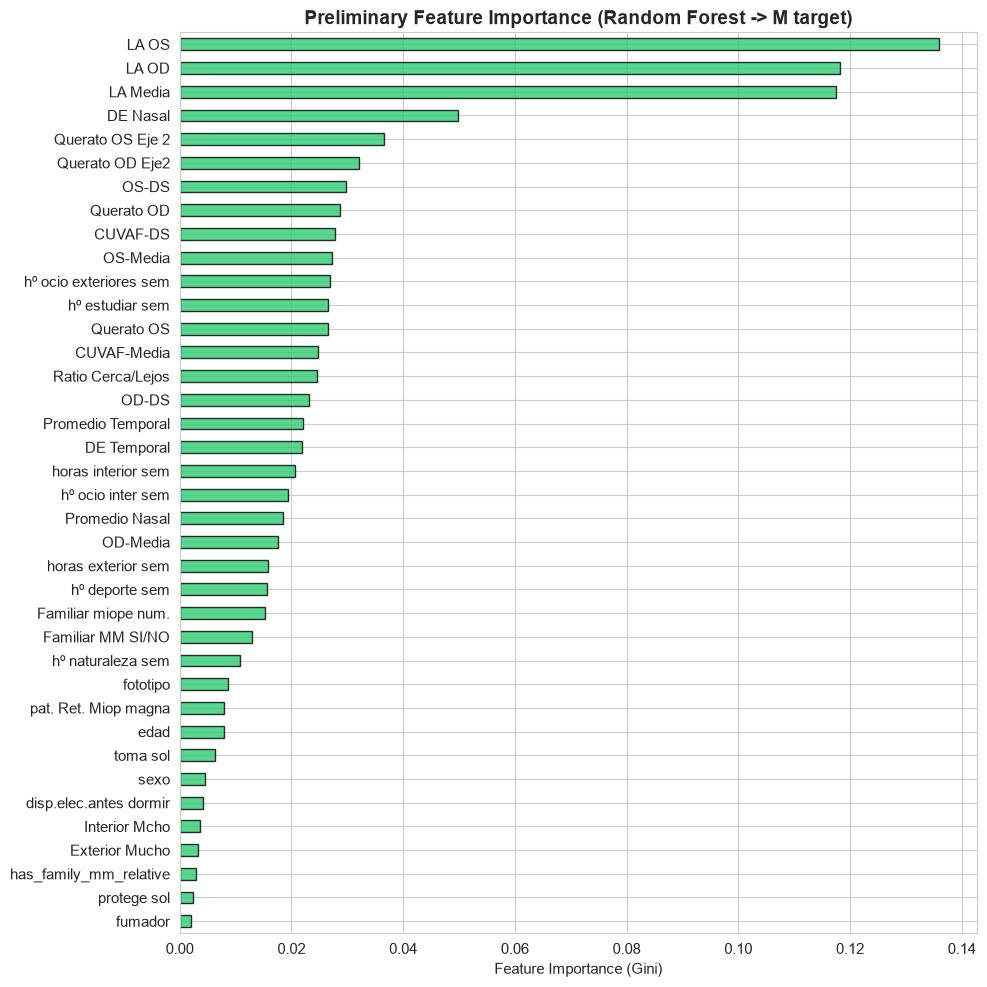


=== Top 15 Most Important Features (for M prediction) ===

  Ratio Cerca/Lejos                    importance = 0.0245
  CUVAF-Media                          importance = 0.0247
  Querato OS                           importance = 0.0265
  hº estudiar sem                      importance = 0.0265
  hº ocio exteriores sem               importance = 0.0269
  OS-Media                             importance = 0.0272
  CUVAF-DS                             importance = 0.0277
  Querato OD                           importance = 0.0288
  OS-DS                                importance = 0.0298
  Querato OD Eje2                      importance = 0.0321
  Querato OS Eje 2                     importance = 0.0366
  DE Nasal                             importance = 0.0498
  LA Media                             importance = 0.1174
  LA OD                                importance = 0.1182
  LA OS                                importance = 0.1359


In [15]:
# Preliminary feature importance using Random Forest (target: M)
rf_prelim = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('rf', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)),
])
rf_prelim.fit(X_train, Y_train['M'])

importances = pd.Series(rf_prelim.named_steps['rf'].feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(10, 10))
importances.plot(kind='barh', color='#2ecc71', edgecolor='black', alpha=0.8)
plt.xlabel('Feature Importance (Gini)')
plt.title('Preliminary Feature Importance (Random Forest -> M target)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top 15 features
print("\n=== Top 15 Most Important Features (for M prediction) ===\n")
for feat, imp in importances.tail(15).items():
    print(f"  {feat:35s}  importance = {imp:.4f}")

### Phase 2 - Summary

After preprocessing, the feature set goes from **49 raw columns to 38 numeric features**:
- Dropped 5 uninformative columns (date, 2 ancestry columns, 100%-missing column, free-text family column).
- Dropped 5 columns that were exact copies of others and the near-constant `Grupo fot`.
- Added `has_family_mm_relative` (replaces the text column `familiar miope magno`).
- Encoded all categorical variables into numeric form and fixed the `CUVAF-Media` typo.
- Missing values are **not** filled here; they are imputed with the training median inside each model's Pipeline.

The preliminary Random Forest shows that the **Axial Length (LA)** measurements are by far the most important features for predicting myopia, followed by the keratometry (Querato) measurements.

> We keep **all remaining features** for all models. Random Forest and Gradient Boosting select features internally; for the SVM, a `StandardScaler` is applied inside the pipeline.

---
## Phase 3: Model Training & Evaluation

### Models used

We train **three different models** for each of the 4 targets. Each one is a `Pipeline` that starts with a `SimpleImputer(strategy='median')`:

| Model | Why we chose it | Key hyperparameters |
|-------|----------------|--------------------|
| **Random Forest** | Robust ensemble of decision trees; handles mixed feature types and high dimensionality; resistant to overfitting with enough trees | 300 trees, min_samples_split=5, balanced class weights |
| **Histogram-based Gradient Boosting** | Builds trees sequentially, each one correcting the errors of the previous ones; often achieves the best accuracy | 300 iterations, max depth 6, lr=0.1, balanced weights |
| **SVM (RBF kernel)** | Effective for small datasets; finds the maximum-margin decision boundary | C=1.0, gamma='scale', StandardScaler, balanced weights |

The hyperparameters are the same as in the original notebook (no tuning yet).

For the SVM we set `probability=True`. An SVM does not output probabilities, only distances to the boundary; with this option scikit-learn fits an extra logistic (sigmoid) function that converts those distances into probabilities. It does **not** change `predict()`. We only need the probabilities in Phase 4, if the SVM is the best DCombo model.

### Cross-validation: `RepeatedStratifiedKFold` (changed)

With 132 samples, a single 5-fold split gives noisy results. Depending on how the students fall into folds, the score can change a lot. This is especially true for MM, where each validation fold contains only **2** positive students. `RepeatedStratifiedKFold(n_splits=5, n_repeats=10)` repeats the stratified 5-fold split **10 times with different shuffles**, so each model is trained and validated **50 times**. The mean of these 50 scores is a much more stable estimate, and the comparison between models depends much less on one lucky or unlucky split.

**Confusion matrices and classification reports** need exactly **one** prediction per student. With repeated CV each student is predicted 10 times, so `cross_val_predict` does not accept it. For these we use a single `StratifiedKFold(n_splits=5)`, which gives one *out-of-fold* prediction per student (a prediction made by a model that did not see that student during training).

### How we select the best model

**For each target independently:**
1. We compute **Accuracy** and **Macro F1-Score** over the 50 validation folds.
2. **The best model is the one with the highest mean Macro F1.**

**Why Macro F1 instead of Accuracy?** Accuracy can be misleading with imbalanced classes. For example, a model that always predicts MM=NO would get 92.4% accuracy (122/132) while missing every positive case. **Macro F1 averages the F1 of every class with the same weight**, so it penalizes models that ignore minority classes.

All models use `class_weight='balanced'` to give more weight to the minority classes during training.

In [16]:
# Cross-validation setup
CV_SCORE = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)  # for the scores
CV_PRED = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)          # for one out-of-fold prediction per student

def get_models():
    '''Return a dictionary of model name -> model (Pipeline with median imputation).'''
    return {
        'Random Forest': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('rf', RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_split=5,
                                          class_weight='balanced', random_state=42, n_jobs=-1)),
        ]),
        'Hist Gradient Boosting': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('hgb', HistGradientBoostingClassifier(max_iter=300, max_depth=6, learning_rate=0.1,
                                                   class_weight='balanced', random_state=42)),
        ]),
        'SVM (RBF)': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', probability=True,
                        class_weight='balanced', random_state=42)),
        ]),
    }

def evaluate_target(X, y, target_name):
    '''Evaluate all models for one target. Returns the CV results, the best model name
    and the out-of-fold predictions of every model.'''
    results = {}
    oof_predictions = {}

    print(f"{'='*65}")
    print(f"  Target: {target_name}")
    print(f"  Classes: { {k: int(v) for k, v in y.value_counts().items()} }")
    print(f"{'='*65}\n")

    for name, model in get_models().items():
        # 50 train/validation splits -> mean and std of the scores
        scores = cross_validate(model, X, y, cv=CV_SCORE,
                                scoring=['accuracy', 'f1_macro'],
                                return_train_score=True)
        results[name] = {
            'train_acc': scores['train_accuracy'].mean(),
            'val_acc': scores['test_accuracy'].mean(),
            'val_acc_std': scores['test_accuracy'].std(),
            'val_f1': scores['test_f1_macro'].mean(),
            'val_f1_std': scores['test_f1_macro'].std(),
        }
        # One out-of-fold prediction per student (for confusion matrices and Phase 4)
        oof_predictions[name] = cross_val_predict(model, X, y, cv=CV_PRED)

        print(f"  {name:25s} | Val Acc: {results[name]['val_acc']:.3f} +/- {results[name]['val_acc_std']:.3f}"
              f" | Val F1: {results[name]['val_f1']:.3f} +/- {results[name]['val_f1_std']:.3f}"
              f" | Train Acc: {results[name]['train_acc']:.3f}")

    # Best model by mean macro F1
    best_name = max(results, key=lambda k: results[k]['val_f1'])
    print(f"\n  >>> Best model for {target_name}: {best_name} "
          f"(F1 = {results[best_name]['val_f1']:.3f})")

    # Confusion matrices (out-of-fold predictions of a single 5-fold split)
    labels = sorted(y.unique())
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for idx, (mname, y_pred) in enumerate(oof_predictions.items()):
        cm_i = confusion_matrix(y, y_pred, labels=labels)
        ConfusionMatrixDisplay(cm_i, display_labels=labels).plot(ax=axes[idx], cmap='Blues', colorbar=False)
        marker = ' *' if mname == best_name else ''
        axes[idx].set_title(f'{mname}{marker}', fontweight='bold')
    plt.suptitle(f'Confusion Matrices (out-of-fold, one 5-fold split) - {target_name}',
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

    # Classification report for the best model
    print(f"\n  Classification Report - {best_name} ({target_name}), out-of-fold predictions:\n")
    print(classification_report(y, oof_predictions[best_name], target_names=labels))

    return results, best_name, oof_predictions

# Store all results
all_results = {}
best_models = {}
oof_best = {}   # out-of-fold predictions of the best model of each target (used in Phase 4)

print("Training functions defined. Ready for model evaluation.")

Training functions defined. Ready for model evaluation.


> **Note:** the F1 in the classification report is computed once over the 132 out-of-fold predictions of a single 5-fold split. It is therefore slightly different from the "Val F1" above, which is the **mean over 50 folds** and is the number we use to select models.

### Target 1: M (Myopia - Binary: SI / NO)

  Target: M (Myopia)
  Classes: {'SI': 88, 'NO': 44}



  Random Forest             | Val Acc: 0.760 +/- 0.075 | Val F1: 0.733 +/- 0.085 | Train Acc: 0.997


  Hist Gradient Boosting    | Val Acc: 0.748 +/- 0.068 | Val F1: 0.710 +/- 0.080 | Train Acc: 1.000


  SVM (RBF)                 | Val Acc: 0.759 +/- 0.074 | Val F1: 0.735 +/- 0.083 | Train Acc: 0.952

  >>> Best model for M (Myopia): SVM (RBF) (F1 = 0.735)


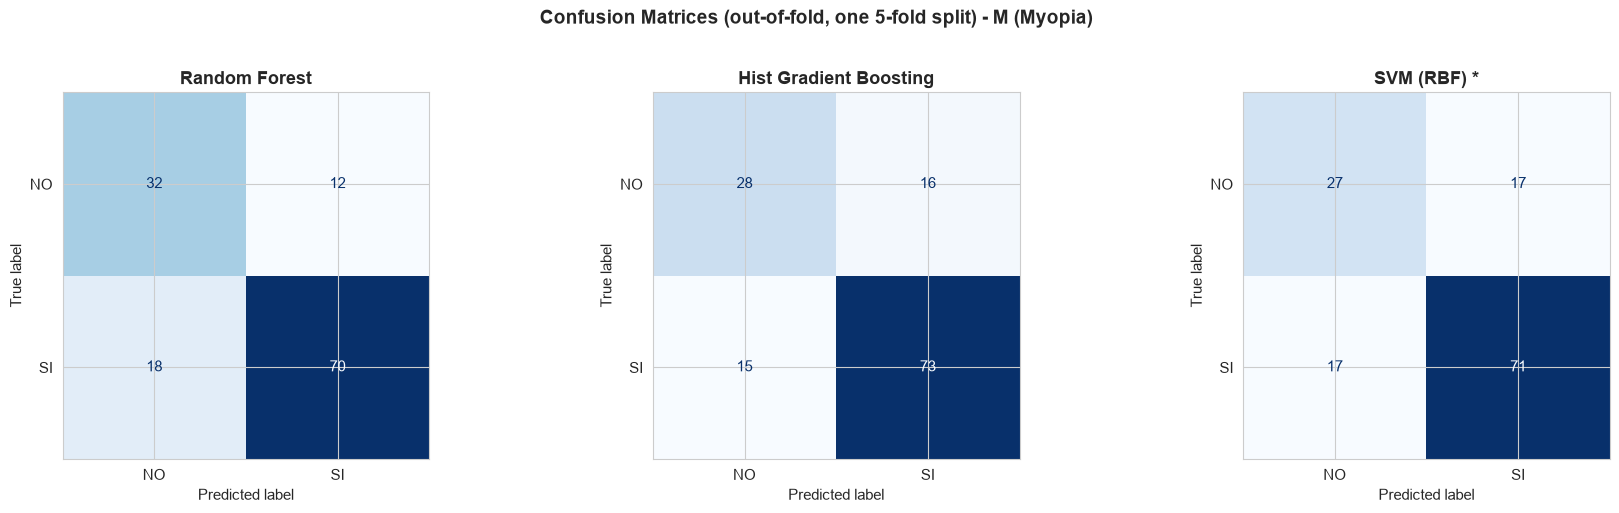


  Classification Report - SVM (RBF) (M (Myopia)), out-of-fold predictions:

              precision    recall  f1-score   support

          NO       0.61      0.61      0.61        44
          SI       0.81      0.81      0.81        88

    accuracy                           0.74       132
   macro avg       0.71      0.71      0.71       132
weighted avg       0.74      0.74      0.74       132



In [17]:
results_M, best_M, oof_M = evaluate_target(X_train, Y_train['M'], 'M (Myopia)')
all_results['M'] = results_M
best_models['M'] = best_M
oof_best['M'] = oof_M[best_M]

### Target 2: MM (Myopia Magna - Binary: SI / NO)

> **Warning:** Heavily imbalanced - only 10 positive samples (7.6%), i.e. 2 per validation fold. Look at the recall of the SI class, not only at the accuracy.

  Target: MM (Myopia Magna)
  Classes: {'NO': 122, 'SI': 10}



  Random Forest             | Val Acc: 0.896 +/- 0.037 | Val F1: 0.624 +/- 0.127 | Train Acc: 0.990


  Hist Gradient Boosting    | Val Acc: 0.896 +/- 0.046 | Val F1: 0.566 +/- 0.137 | Train Acc: 1.000


  SVM (RBF)                 | Val Acc: 0.940 +/- 0.029 | Val F1: 0.675 +/- 0.190 | Train Acc: 1.000

  >>> Best model for MM (Myopia Magna): SVM (RBF) (F1 = 0.675)


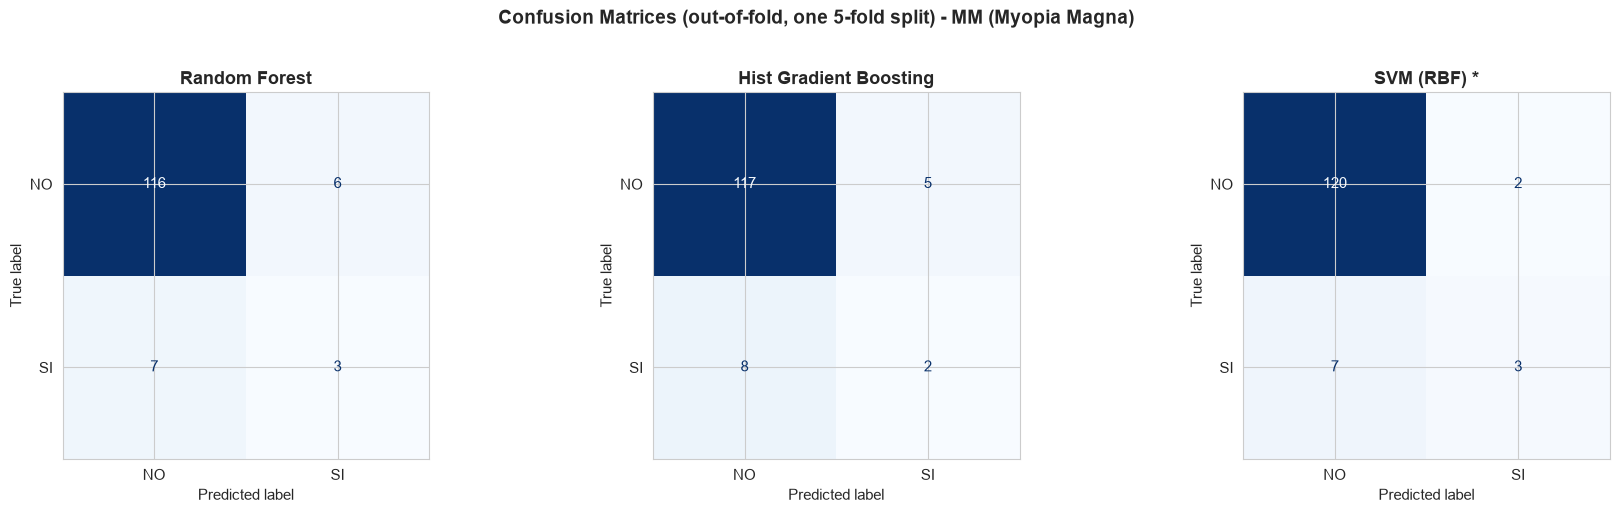


  Classification Report - SVM (RBF) (MM (Myopia Magna)), out-of-fold predictions:

              precision    recall  f1-score   support

          NO       0.94      0.98      0.96       122
          SI       0.60      0.30      0.40        10

    accuracy                           0.93       132
   macro avg       0.77      0.64      0.68       132
weighted avg       0.92      0.93      0.92       132



In [18]:
results_MM, best_MM, oof_MM = evaluate_target(X_train, Y_train['MM'], 'MM (Myopia Magna)')
all_results['MM'] = results_MM
best_models['MM'] = best_MM
oof_best['MM'] = oof_MM[best_MM]

### Target 3: Combo (Multi-class: C / M / MM)

> In Phase 4 the final Combo is **derived from DCombo** (Combo = merge(DCombo)). We still evaluate Combo models here, as a reference to check that deriving Combo from DCombo does not lose accuracy.

  Target: Combo
  Classes: {'M': 70, 'C': 44, 'MM': 18}



  Random Forest             | Val Acc: 0.719 +/- 0.097 | Val F1: 0.732 +/- 0.093 | Train Acc: 0.990


  Hist Gradient Boosting    | Val Acc: 0.620 +/- 0.077 | Val F1: 0.599 +/- 0.081 | Train Acc: 1.000


  SVM (RBF)                 | Val Acc: 0.675 +/- 0.084 | Val F1: 0.674 +/- 0.083 | Train Acc: 0.931

  >>> Best model for Combo: Random Forest (F1 = 0.732)


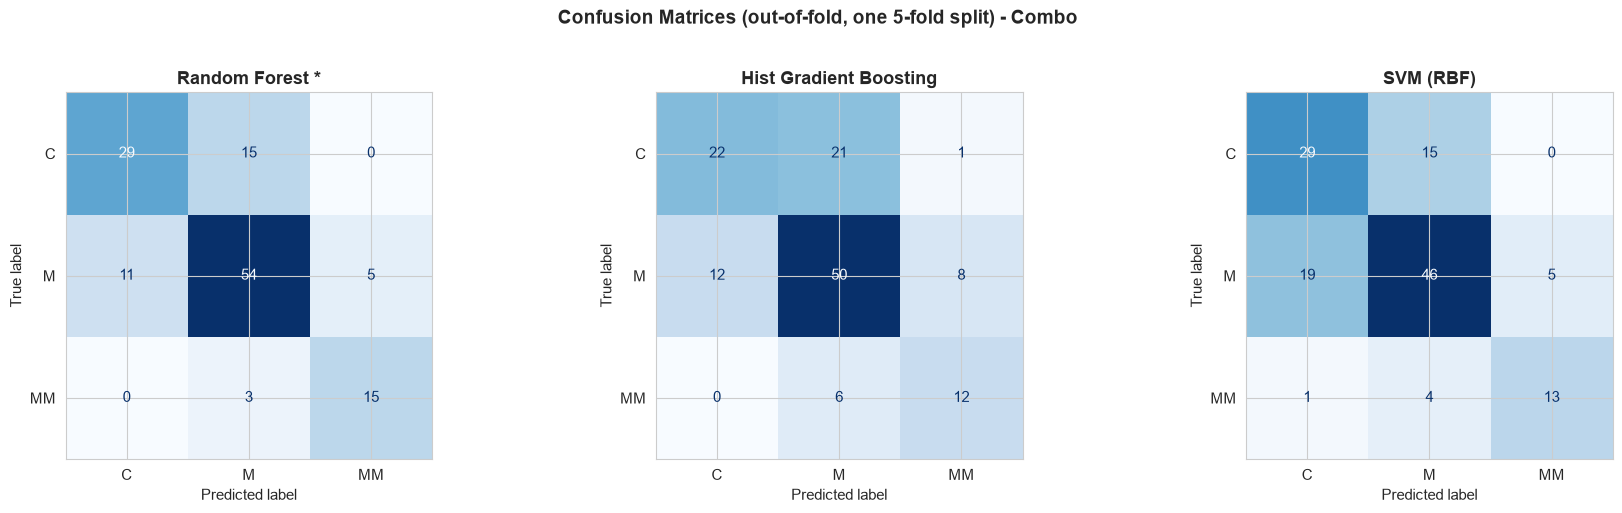


  Classification Report - Random Forest (Combo), out-of-fold predictions:

              precision    recall  f1-score   support

           C       0.72      0.66      0.69        44
           M       0.75      0.77      0.76        70
          MM       0.75      0.83      0.79        18

    accuracy                           0.74       132
   macro avg       0.74      0.75      0.75       132
weighted avg       0.74      0.74      0.74       132



In [19]:
results_Combo, best_Combo, oof_Combo = evaluate_target(X_train, Y_train['Combo'], 'Combo')
all_results['Combo'] = results_Combo
best_models['Combo'] = best_Combo
oof_best['Combo'] = oof_Combo[best_Combo]

### Target 4: DCombo (Multi-class: C / M1 / M2 / MM)

  Target: DCombo
  Classes: {'C': 44, 'M1': 39, 'M2': 31, 'MM': 18}



  Random Forest             | Val Acc: 0.556 +/- 0.086 | Val F1: 0.582 +/- 0.080 | Train Acc: 1.000


  Hist Gradient Boosting    | Val Acc: 0.477 +/- 0.074 | Val F1: 0.476 +/- 0.081 | Train Acc: 1.000


  SVM (RBF)                 | Val Acc: 0.503 +/- 0.077 | Val F1: 0.502 +/- 0.086 | Train Acc: 0.939

  >>> Best model for DCombo: Random Forest (F1 = 0.582)


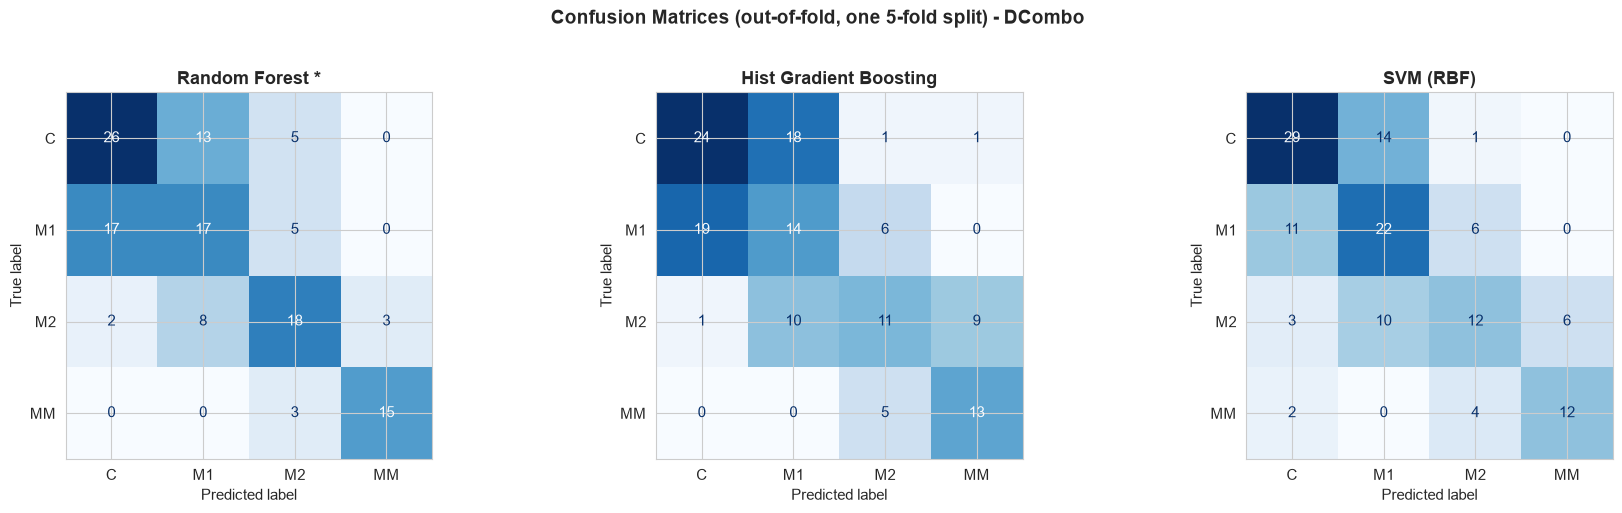


  Classification Report - Random Forest (DCombo), out-of-fold predictions:

              precision    recall  f1-score   support

           C       0.58      0.59      0.58        44
          M1       0.45      0.44      0.44        39
          M2       0.58      0.58      0.58        31
          MM       0.83      0.83      0.83        18

    accuracy                           0.58       132
   macro avg       0.61      0.61      0.61       132
weighted avg       0.57      0.58      0.58       132



In [20]:
results_DCombo, best_DCombo, oof_DCombo = evaluate_target(X_train, Y_train['DCombo'], 'DCombo')
all_results['DCombo'] = results_DCombo
best_models['DCombo'] = best_DCombo
oof_best['DCombo'] = oof_DCombo[best_DCombo]


  SUMMARY: Best Model per Target (RepeatedStratifiedKFold, 5 folds x 10 repeats)


Target    Best Model    Val Accuracy  Val F1 (macro)
     M     SVM (RBF) 0.759 +/- 0.074 0.735 +/- 0.083
    MM     SVM (RBF) 0.940 +/- 0.029 0.675 +/- 0.190
 Combo Random Forest 0.719 +/- 0.097 0.732 +/- 0.093
DCombo Random Forest 0.556 +/- 0.086 0.582 +/- 0.080


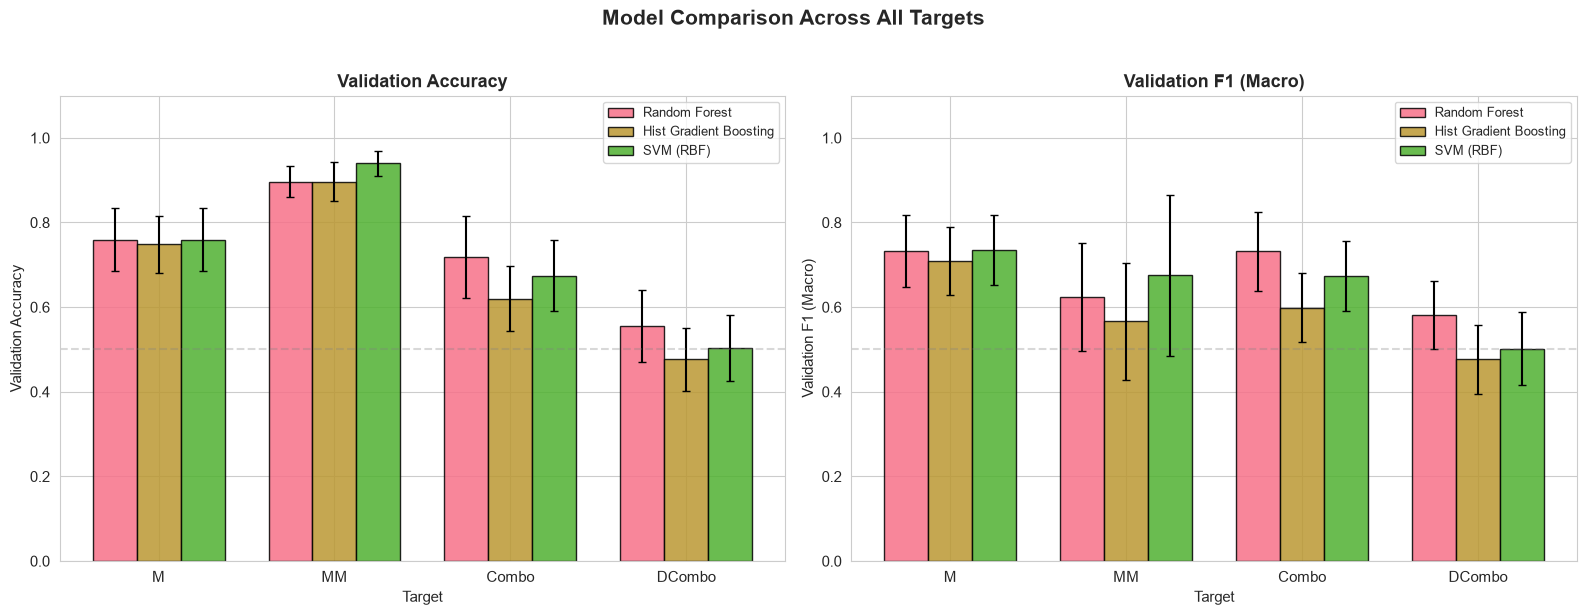

In [21]:
# === Summary of All Results ===
print("\n" + "="*80)
print("  SUMMARY: Best Model per Target (RepeatedStratifiedKFold, 5 folds x 10 repeats)")
print("="*80)

summary_rows = []
for target in ['M', 'MM', 'Combo', 'DCombo']:
    best = best_models[target]
    r = all_results[target][best]
    summary_rows.append({
        'Target': target,
        'Best Model': best,
        'Val Accuracy': f"{r['val_acc']:.3f} +/- {r['val_acc_std']:.3f}",
        'Val F1 (macro)': f"{r['val_f1']:.3f} +/- {r['val_f1_std']:.3f}",
    })

summary_df = pd.DataFrame(summary_rows)
print("\n")
print(summary_df.to_string(index=False))

# Detailed comparison chart (error bars = std over the 50 folds)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
targets = ['M', 'MM', 'Combo', 'DCombo']
model_names = list(get_models().keys())
x = np.arange(len(targets))
width = 0.25

for metric_idx, (metric, title) in enumerate([('val_acc', 'Validation Accuracy'), ('val_f1', 'Validation F1 (Macro)')]):
    ax = axes[metric_idx]
    for i, mname in enumerate(model_names):
        vals = [all_results[t][mname][metric] for t in targets]
        stds = [all_results[t][mname][metric + '_std'] for t in targets]
        ax.bar(x + i*width, vals, width, yerr=stds, capsize=3, label=mname, alpha=0.85, edgecolor='black')
    ax.set_xlabel('Target')
    ax.set_ylabel(title)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xticks(x + width)
    ax.set_xticklabels(targets)
    ax.legend(fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.3)

plt.suptitle('Model Comparison Across All Targets', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [22]:
# === Explicit Model Selection Summary ===
print("=" * 70)
print("  BEST MODEL SELECTED FOR EACH TARGET")
print("  (Selected by highest mean Macro F1-Score over 5x10 repeated CV)")
print("=" * 70)

for target in ['M', 'MM', 'Combo', 'DCombo']:
    best = best_models[target]
    r = all_results[target][best]
    print(f"\n  Target: {target}")
    print(f"  Winner: {best}")
    print(f"  Macro F1: {r['val_f1']:.3f} +/- {r['val_f1_std']:.3f}")
    print(f"  Accuracy: {r['val_acc']:.3f} +/- {r['val_acc_std']:.3f}")
    print(f"  All models compared:")
    for mname, mresult in all_results[target].items():
        flag = ' <-- SELECTED' if mname == best else ''
        print(f"    {mname:25s} F1={mresult['val_f1']:.3f}  Acc={mresult['val_acc']:.3f}{flag}")

print("\n" + "=" * 70)
print("  M, MM and DCombo models are used in Phase 4 (Combo is derived from DCombo).")
print("=" * 70)

  BEST MODEL SELECTED FOR EACH TARGET
  (Selected by highest mean Macro F1-Score over 5x10 repeated CV)

  Target: M
  Winner: SVM (RBF)
  Macro F1: 0.735 +/- 0.083
  Accuracy: 0.759 +/- 0.074
  All models compared:
    Random Forest             F1=0.733  Acc=0.760
    Hist Gradient Boosting    F1=0.710  Acc=0.748
    SVM (RBF)                 F1=0.735  Acc=0.759 <-- SELECTED

  Target: MM
  Winner: SVM (RBF)
  Macro F1: 0.675 +/- 0.190
  Accuracy: 0.940 +/- 0.029
  All models compared:
    Random Forest             F1=0.624  Acc=0.896
    Hist Gradient Boosting    F1=0.566  Acc=0.896
    SVM (RBF)                 F1=0.675  Acc=0.940 <-- SELECTED

  Target: Combo
  Winner: Random Forest
  Macro F1: 0.732 +/- 0.093
  Accuracy: 0.719 +/- 0.097
  All models compared:
    Random Forest             F1=0.732  Acc=0.719 <-- SELECTED
    Hist Gradient Boosting    F1=0.599  Acc=0.620
    SVM (RBF)                 F1=0.674  Acc=0.675

  Target: DCombo
  Winner: Random Forest
  Macro F1: 0.582 +/

### Phase 3 - Summary & Model Selection Rationale

Each target was evaluated with 3 models using **5-fold stratified CV repeated 10 times** (50 validation folds per model). The best model per target is the one with the **highest mean Macro F1-Score**.

**Why this approach works:**
- We evaluate each target **independently**, because each one has a different class distribution and difficulty.
- A model that works best for binary myopia detection (M) may not be the best for 4-class sub-typing (DCombo).
- Macro F1 (not accuracy) makes sure the selected model also performs well on the **rare classes**.

**Caveat:** the standard deviations across folds are large compared with the differences between some models, so a small difference in mean F1 should not be over-interpreted. Also, because we choose the winner using the same CV scores that we report, the reported score of the winner is slightly optimistic.

---
## Phase 4: Final Predictions on Test Set

### Post-processing: enforcing the logical constraints (changed)

The models for M, MM and DCombo are trained independently, so their predictions can contradict each other. We enforce the three constraints from Phase 1, applying the rules **in this order** for each student:

| Rule | Condition | Action |
|------|-----------|--------|
| **Rule 1** | MM=SI | Force **DCombo=MM** (and therefore M=SI, because M=NO ⇔ DCombo=C) |
| **Rule 2** | M=NO (and MM=NO) | Force **DCombo=C** |
| **Rule 3** | M=SI, MM=NO, but DCombo=C | Replace DCombo with the **most probable myopic class** (M1, M2 or MM) according to the DCombo model's `predict_proba` |
| **Rule 4** | Always | **Combo = merge(DCombo)**: C → C, M1/M2 → M, MM → MM |

Notes:
- If MM=NO, DCombo=MM is **allowed** (8 training students are like that), so we do not touch it. This is the main difference with the original notebook.
- If the MM model says SI but the M model says NO, the two binary models contradict each other. We give priority to MM=SI (Rule 1 is applied first) because it is a very specific prediction (the MM model rarely predicts SI). The validation below shows how many students each rule changes.
- In Rule 3, the original notebook always chose M1. We now use the probabilities of the DCombo model, restricted to the classes allowed by the constraints.

### Validating the post-processing

Instead of assuming that the rules help, we **apply them to the out-of-fold predictions** of the training set (Phase 3) and compare the scores before and after. For Combo, "before" is the dedicated Combo model and "after" is merge(DCombo).

In [23]:
MERGE_DCOMBO = {'C': 'C', 'M1': 'M', 'M2': 'M', 'MM': 'MM'}

def apply_constraints(pred_M, pred_MM, pred_DCombo, dcombo_proba, dcombo_classes, verbose=False):
    '''
    Make the 4 predictions consistent.
    dcombo_proba: (n_samples x n_classes) probabilities of the DCombo model,
                  columns in the order of dcombo_classes.
    Returns a dict with the 4 corrected predictions and the number of changes per rule.
    '''
    m, mm, dcombo = list(pred_M), list(pred_MM), list(pred_DCombo)
    myopic_classes = [c for c in dcombo_classes if c != 'C']
    changes = {'Rule 1': 0, 'Rule 2': 0, 'Rule 3': 0}

    for i in range(len(m)):
        # Rule 1: MM=SI => DCombo=MM (and M=SI)
        if mm[i] == 'SI':
            if dcombo[i] != 'MM' or m[i] != 'SI':
                if verbose:
                    print(f"  Sample {i}: MM=SI but M={m[i]}, DCombo={dcombo[i]} -> forcing M=SI, DCombo=MM")
                changes['Rule 1'] += 1
            dcombo[i] = 'MM'
            m[i] = 'SI'

        # Rule 2: M=NO => DCombo=C
        elif m[i] == 'NO':
            if dcombo[i] != 'C':
                if verbose:
                    print(f"  Sample {i}: M=NO but DCombo={dcombo[i]} -> forcing DCombo=C")
                changes['Rule 2'] += 1
                dcombo[i] = 'C'

        # Rule 3: M=SI => DCombo must not be C -> most probable myopic class
        elif dcombo[i] == 'C':
            probs = dict(zip(dcombo_classes, dcombo_proba[i]))
            new_class = max(myopic_classes, key=lambda c: probs[c])
            if verbose:
                print(f"  Sample {i}: M=SI but DCombo=C -> forcing DCombo={new_class} "
                      f"(P={probs[new_class]:.2f} among {myopic_classes})")
            changes['Rule 3'] += 1
            dcombo[i] = new_class

    # Rule 4: Combo = merge(DCombo)
    combo = [MERGE_DCOMBO[d] for d in dcombo]
    return {'M': m, 'MM': mm, 'Combo': combo, 'DCombo': dcombo}, changes

print("Constraint function defined.")

Constraint function defined.


In [24]:
# Out-of-fold probabilities of the best DCombo model (same CV_PRED split as its oof predictions)
dcombo_classes = sorted(Y_train['DCombo'].unique())   # cross_val_predict orders the columns like this
oof_dcombo_proba = cross_val_predict(get_models()[best_models['DCombo']], X_train, Y_train['DCombo'],
                                     cv=CV_PRED, method='predict_proba')

# How many students have inconsistent predictions BEFORE post-processing?
before = oof_best
inconsistent = sum(
    (before['MM'][i] == 'SI' and before['DCombo'][i] != 'MM')
    or ((before['M'][i] == 'NO') != (before['DCombo'][i] == 'C'))
    or (before['Combo'][i] != MERGE_DCOMBO[before['DCombo'][i]])
    for i in range(len(Y_train))
)
print(f"Students with inconsistent out-of-fold predictions before post-processing: {inconsistent} / {len(Y_train)}")

after, oof_changes = apply_constraints(before['M'], before['MM'], before['DCombo'],
                                       oof_dcombo_proba, dcombo_classes)
print(f"Corrections made by each rule: {oof_changes}")

# Compare scores before vs after (out-of-fold, so this is an honest estimate)
rows = []
for target in ['M', 'MM', 'Combo', 'DCombo']:
    y_true = Y_train[target]
    rows.append({
        'Target': target,
        'Acc before': accuracy_score(y_true, before[target]),
        'Acc after': accuracy_score(y_true, after[target]),
        'F1 before': f1_score(y_true, before[target], average='macro'),
        'F1 after': f1_score(y_true, after[target], average='macro'),
    })
validation_df = pd.DataFrame(rows).set_index('Target').round(3)
print("\n=== Out-of-fold scores before vs after the constraints ===")
print("(Combo 'before' = dedicated Combo model, Combo 'after' = merge(DCombo))\n")
print(validation_df.to_string())

Students with inconsistent out-of-fold predictions before post-processing: 34 / 132
Corrections made by each rule: {'Rule 1': 3, 'Rule 2': 10, 'Rule 3': 11}

=== Out-of-fold scores before vs after the constraints ===
(Combo 'before' = dedicated Combo model, Combo 'after' = merge(DCombo))

        Acc before  Acc after  F1 before  F1 after
Target                                            
M            0.742      0.742      0.710     0.710
MM           0.932      0.932      0.682     0.682
Combo        0.742      0.689      0.747     0.704
DCombo       0.576      0.591      0.610     0.615


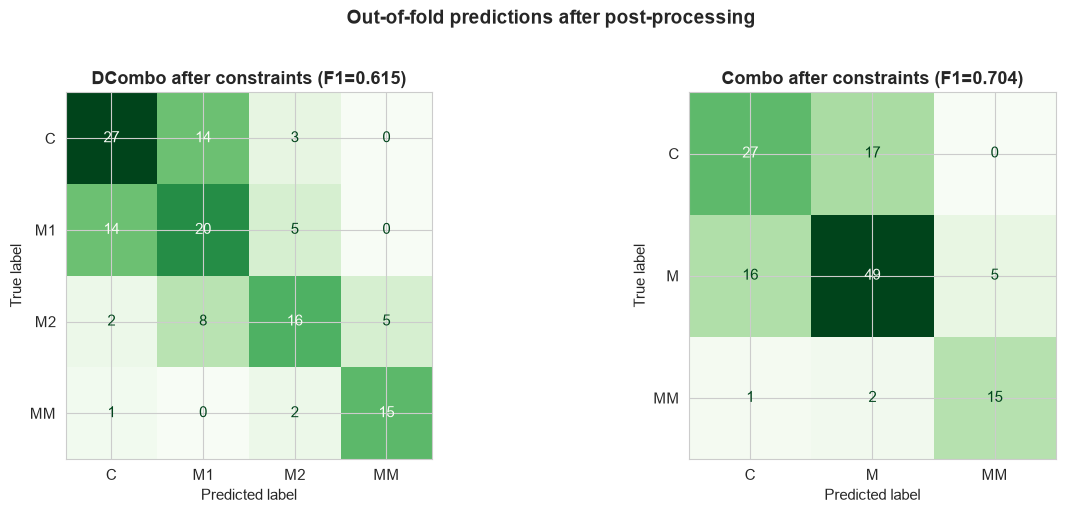

In [25]:
# Confusion matrices of DCombo and Combo after the constraints (out-of-fold)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, target in zip(axes, ['DCombo', 'Combo']):
    labels = sorted(Y_train[target].unique())
    cm_i = confusion_matrix(Y_train[target], after[target], labels=labels)
    ConfusionMatrixDisplay(cm_i, display_labels=labels).plot(ax=ax, cmap='Greens', colorbar=False)
    ax.set_title(f'{target} after constraints '
                 f'(F1={f1_score(Y_train[target], after[target], average="macro"):.3f})', fontweight='bold')
plt.suptitle('Out-of-fold predictions after post-processing', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Training the final models and predicting the test set

For M, MM and DCombo we:
1. Take the **best model selected in Phase 3**.
2. **Re-train it on the full training set** (all 132 samples). During CV each model only used 80% of the data; now it uses 100%.
3. **Predict** the 24 unlabeled test samples (and the DCombo probabilities, needed by Rule 3).

The final Combo is obtained from DCombo with Rule 4. The test set is imputed with the **training** medians stored inside each pipeline.

In [26]:
# Train the best models on the full training set and predict the test set
final_models = {}
raw_predictions = {}

for target in ['M', 'MM', 'DCombo']:
    best_name = best_models[target]
    model = get_models()[best_name]
    model.fit(X_train, Y_train[target])
    final_models[target] = model
    raw_predictions[target] = model.predict(X_test)
    counts = {k: int(v) for k, v in pd.Series(raw_predictions[target]).value_counts().items()}
    print(f"Target {target:7s} | Model: {best_name:25s} | Predictions: {counts}")

# DCombo probabilities on the test set (columns ordered as model.classes_)
dcombo_test_proba = final_models['DCombo'].predict_proba(X_test)
test_dcombo_classes = list(final_models['DCombo'].classes_)

print("\nAll predictions generated (before constraint enforcement).")

Target M       | Model: SVM (RBF)                 | Predictions: {'SI': 16, 'NO': 8}
Target MM      | Model: SVM (RBF)                 | Predictions: {'NO': 23, 'SI': 1}


Target DCombo  | Model: Random Forest             | Predictions: {'C': 8, 'M1': 7, 'MM': 5, 'M2': 4}

All predictions generated (before constraint enforcement).


In [27]:
# Apply the logical constraints to the test predictions
print("=== Applying Logical Constraints ===\n")
predictions, test_changes = apply_constraints(raw_predictions['M'], raw_predictions['MM'],
                                              raw_predictions['DCombo'], dcombo_test_proba,
                                              test_dcombo_classes, verbose=True)

print(f"\nCorrections per rule: {test_changes}  (total = {sum(test_changes.values())})")
print("\n=== Final Prediction Distributions (after constraints) ===\n")
for target in ['M', 'MM', 'Combo', 'DCombo']:
    counts = {k: int(v) for k, v in pd.Series(predictions[target]).value_counts().items()}
    print(f"  {target:7s}: {counts}")

# Final check: the constraints hold for every test student
pred_df = pd.DataFrame(predictions)[['M', 'MM', 'Combo', 'DCombo']]
assert ((pred_df['MM'] == 'SI') <= (pred_df['DCombo'] == 'MM')).all()
assert ((pred_df['M'] == 'NO') == (pred_df['DCombo'] == 'C')).all()
assert (pred_df['Combo'] == pred_df['DCombo'].map(MERGE_DCOMBO)).all()
print("\nAll constraints verified on the test predictions.")

=== Applying Logical Constraints ===

  Sample 1: M=NO but DCombo=M1 -> forcing DCombo=C
  Sample 4: M=SI but DCombo=C -> forcing DCombo=M1 (P=0.36 among ['M1', 'M2', 'MM'])
  Sample 6: M=NO but DCombo=M2 -> forcing DCombo=C
  Sample 17: M=SI but DCombo=C -> forcing DCombo=M1 (P=0.43 among ['M1', 'M2', 'MM'])

Corrections per rule: {'Rule 1': 0, 'Rule 2': 2, 'Rule 3': 2}  (total = 4)

=== Final Prediction Distributions (after constraints) ===

  M      : {'SI': 16, 'NO': 8}
  MM     : {'NO': 23, 'SI': 1}
  Combo  : {'M': 11, 'C': 8, 'MM': 5}
  DCombo : {'C': 8, 'M1': 8, 'MM': 5, 'M2': 3}

All constraints verified on the test predictions.


In [28]:
# Save predictions to TXT file (tab-separated, one column per target)
pred_df.to_csv('test_predictions_fixes.txt', sep='\t', index=False)

print("Predictions saved to 'test_predictions_fixes.txt'")
print("\nFinal predictions table:")
print(pred_df.to_string(index=True))
print(f"\nTotal test samples: {len(pred_df)}")

Predictions saved to 'test_predictions_fixes.txt'

Final predictions table:
     M  MM Combo DCombo
0   SI  NO    MM     MM
1   NO  NO     C      C
2   SI  SI    MM     MM
3   SI  NO     M     M1
4   SI  NO     M     M1
5   NO  NO     C      C
6   NO  NO     C      C
7   SI  NO    MM     MM
8   SI  NO     M     M1
9   SI  NO    MM     MM
10  NO  NO     C      C
11  NO  NO     C      C
12  SI  NO     M     M1
13  SI  NO     M     M1
14  SI  NO     M     M1
15  SI  NO    MM     MM
16  SI  NO     M     M2
17  SI  NO     M     M1
18  NO  NO     C      C
19  SI  NO     M     M2
20  SI  NO     M     M1
21  NO  NO     C      C
22  SI  NO     M     M2
23  NO  NO     C      C

Total test samples: 24


---
## Phase 5: Summary & Conclusions

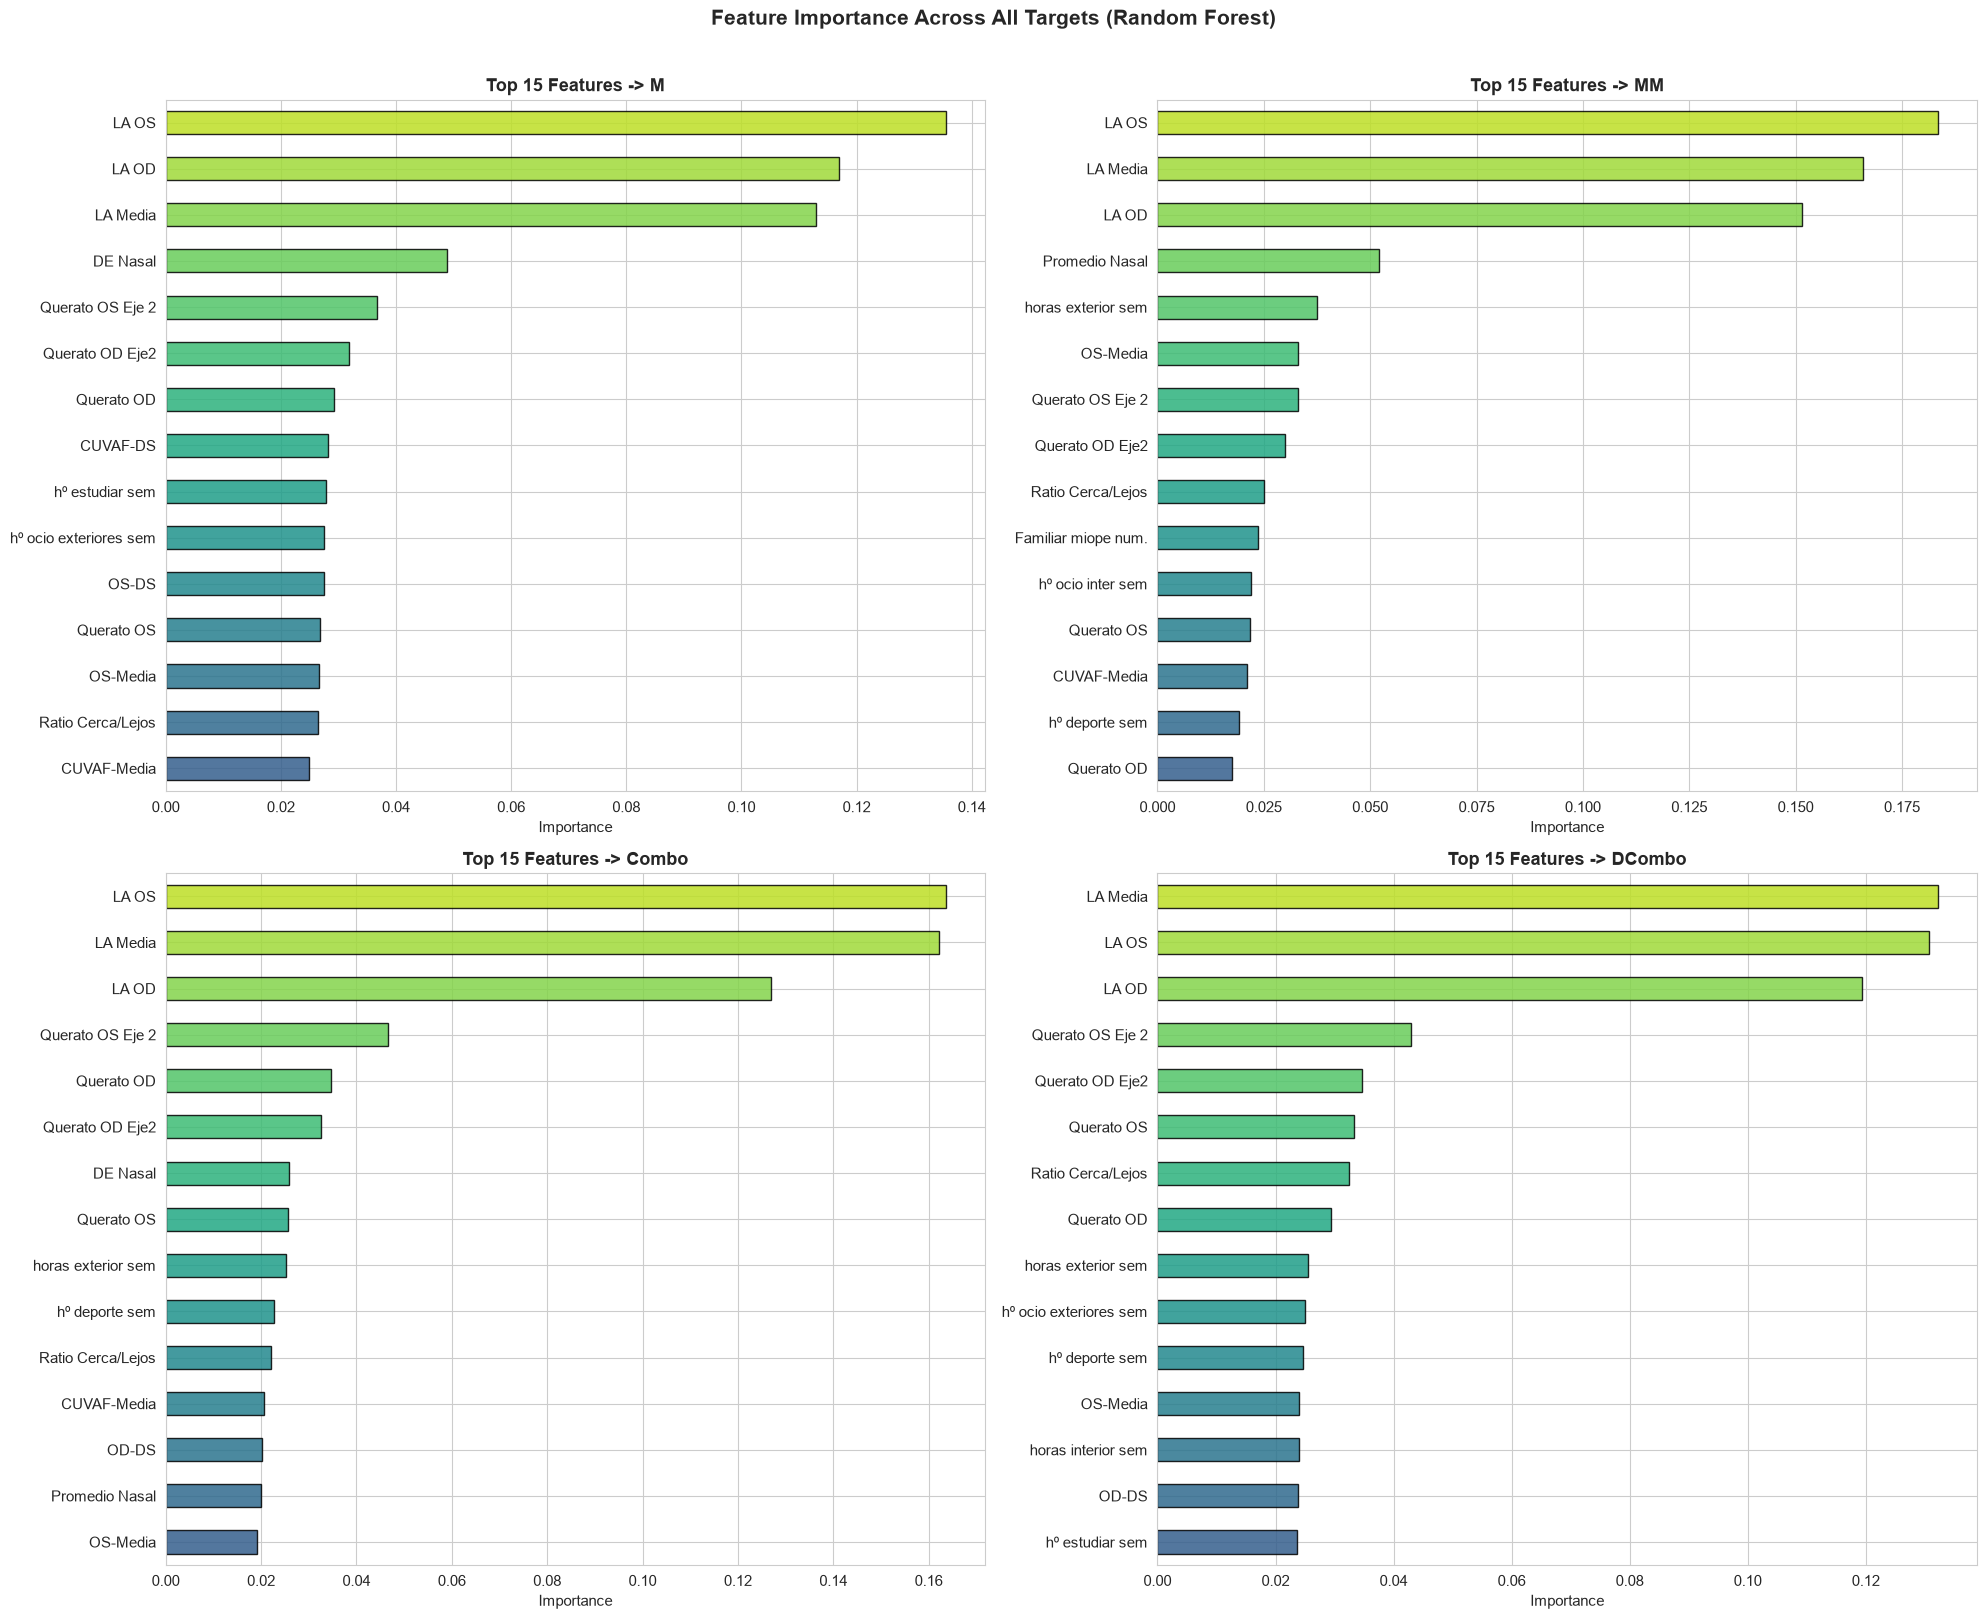

In [29]:
# Feature importance for all 4 targets using Random Forest
# (Random Forest is used for all targets because it provides importances directly,
#  even for targets where another model was selected)
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
for idx, target in enumerate(['M', 'MM', 'Combo', 'DCombo']):
    ax = axes[idx // 2][idx % 2]
    rf = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('rf', RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1)),
    ])
    rf.fit(X_train, Y_train[target])
    imp = pd.Series(rf.named_steps['rf'].feature_importances_, index=X_train.columns).sort_values(ascending=True)
    imp.tail(15).plot(kind='barh', ax=ax, color=plt.cm.viridis(np.linspace(0.3, 0.9, 15)),
                      edgecolor='black', alpha=0.85)
    ax.set_title(f'Top 15 Features -> {target}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance')
plt.suptitle('Feature Importance Across All Targets (Random Forest)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Conclusions

1. **Data Preprocessing**: Starting from 49 raw columns, we kept **38 numeric features**. We dropped the date, ancestry and 100%-missing columns, 5 columns that were exact copies of others and the near-constant `Grupo fot`. We fixed a typo in `CUVAF-Media` (test row 0) and encoded all categoricals. Missing values are imputed with the training median **inside each pipeline**, so cross-validation has no leakage and the test set is filled with training statistics only.

2. **Key Predictive Features**:
   - **Axial Length (LA OD, LA OS, LA Media)** is by far the strongest predictor for every target.
   - **Keratometry (Querato)** and the **OD/OS/CUVAF and Nasal/Temporal** measurements follow.
   - Lifestyle factors (hours of study, outdoor/indoor hours) have lower but non-negligible importance.

3. **Model Performance** (mean over 5x10 repeated stratified CV):

   | Target | Best model | Macro F1 | Accuracy |
   |--------|-----------|----------|----------|
   | M | SVM (RBF) | 0.735 ± 0.083 | 0.759 ± 0.074 |
   | MM | SVM (RBF) | 0.675 ± 0.190 | 0.940 ± 0.029 |
   | Combo | Random Forest | 0.732 ± 0.093 | 0.719 ± 0.097 |
   | DCombo | Random Forest | 0.582 ± 0.080 | 0.556 ± 0.086 |

   - For **M**, SVM and Random Forest are practically tied (0.735 vs 0.733, far below one standard deviation). The choice between them is not meaningful.
   - **MM** is the most difficult target: the high accuracy hides that only **3 of the 10** MM=SI students are detected (recall 0.30 out-of-fold). The fold-to-fold standard deviation (0.19) is also the largest.
   - **DCombo** is the most complex task. The MM class is recognised well (F1 ≈ 0.83), but **M1 vs M2** is hard to separate (F1 ≈ 0.44 for M1).
   - Repeated CV changed the picture slightly with respect to the original single 5-fold split. For example, the M winner changed from Random Forest to SVM, which confirms that the single-split ranking was partly noise.

4. **Post-Processing** (validated on out-of-fold predictions):
   - Before post-processing, **34 of 132** students had inconsistent predictions across the 4 targets. After it, every prediction satisfies MM=SI ⇒ DCombo=MM, M=NO ⇔ DCombo=C and Combo = merge(DCombo).
   - The rules leave M and MM unchanged and slightly **improve DCombo** (F1 0.610 → 0.615, accuracy 0.576 → 0.591).
   - Deriving **Combo from DCombo lowers the Combo score** (F1 0.747 → 0.704, accuracy 0.742 → 0.689). The dedicated Combo model (3 classes) is more accurate than the DCombo model (4 classes) at deciding C / M / MM. Consistency therefore has a cost here.
   - On the test set, 4 predictions were corrected (2 by Rule 2, 2 by Rule 3). Unlike in the original notebook, the 4 students for whom DCombo predicted MM while the MM model said NO keep their DCombo/Combo = MM label.

5. **Predictions**: The final test predictions are saved to `test_predictions_fixes.txt`.

6. **Possible next steps**:
   - **Hyperparameter tuning** (e.g. `GridSearchCV` inside the cross-validation) - all models still use the original hand-picked values.
   - An alternative consistent scheme that may recover the Combo accuracy: let the **Combo model decide C / M / MM** and use DCombo only to split M into M1 / M2. Comparing it with the current scheme on out-of-fold predictions would show which one is better.
   - Improving **MM recall**, for example by lowering the decision threshold of the MM model, measured with the same out-of-fold procedure.

---
*Notebook for the ML Course 2026/27 - University of Navarra*